# Owning ≠ Playing: Predicting What Steam Users Actually Play
**MGTA 461 / CSE 158-258, Assignment 2**

Steam users buy far more games than they play. Given a user's library, we predict
1. **how long** they play each game they own (main task, regression),
2. **whether** they play it at all, or are playing it right now (classification), and
3. **which new games** to recommend that they would actually *play*, not just buy (ranking).

All three tasks share **one data pipeline, one leak-free split and one evaluation module**.

| Section | Rubric part |
|---|---|
| [1. Predictive task](#1.-Predictive-task) | task, evaluation, baselines, validity |
| [2. Data & EDA](#2.-Data,-preprocessing-and-exploratory-analysis) | source, preprocessing, exploration |
| [3. Modeling](#3.-Modeling) | formulation, model ladder, code walkthrough, trade-offs |
| [4. Evaluation](#4.-Evaluation) | metrics, baselines, results, ablations, bias, errors |
| [5. Related work](#5.-Related-work) | prior use of this data and these methods |

*How this notebook runs:* the heavy lifting lives in the `steam/` package (one module per task).
Each stage caches its outputs in `artifacts/`, so this notebook re-runs only stages
whose outputs are missing, then reads the results and draws every figure. Model code is
printed inline (`show_code`) so you can follow the walkthrough without opening other files.

In [1]:
import ast, os, subprocess, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from steam import viz, eda, report, splits, features
viz.setup()
pd.set_option("display.max_colwidth", 120)

def show_code(path, *names):
    # Print selected classes/functions from a source file (the single source of truth)
    src = (ROOT / path).read_text(); lines = src.splitlines()
    for node in ast.parse(src).body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
            seg = "\n".join(lines[node.lineno - 1: node.end_lineno])
            display(Markdown(f"`{path}` → `{node.name}`\n```python\n{seg}\n```"))

# run any pipeline stage whose cached output is missing (each stage in its own process)
out = subprocess.run([sys.executable, "scripts/run_all.py"], capture_output=True, text=True)
print(out.stdout[-2000:], out.stderr[-2000:] if out.returncode else "")

--- data: cached (interactions.parquet)
--- splits: cached (train.parquet)
--- regression_cf: cached (reg_base_test.parquet)
--- ranking: cached (results/ranking.json)
--- regression_nn: cached (results/regression_nn.json)
--- regression_stack: cached (results/regression.json)
--- classify: cached (results/classification.json)
--- ranking_ltr: cached (results/ranking_ltr.json)
 


# 1. Predictive task

**Core story:** *owning a game isn't the same as playing it.* Over a third of the games in
Steam libraries have never been launched. A store that recommends games people will **play**
(not just buy) needs to model engagement, not ownership.

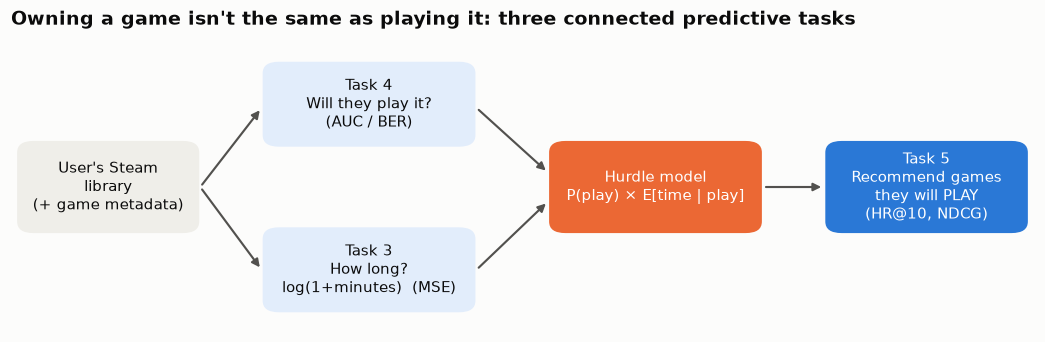

In [2]:
report.fig_pipeline(); plt.show()

In [3]:
report.table_tasks()

,Task,Question,Formulation,Metric,Baselines to beat
0,3 (main),Hours played,Regression on y = log(1 + minutes) for owned pairs,"MSE (primary), MAE","Global / user / game mean, bias model"
1,4,Will they play it?,Binary: playtime > 0 (also: active in last 2 weeks),"AUC, BER (threshold set on valid)","Game / user play-rate, logistic regression"
2,5,Recommend games they'll play,Ranking over games; positive = played,"AUC, HR@10, NDCG@10; coverage, novelty","Random, most-popular, Jaccard item-kNN"


**Why these targets and metrics**
- **Regression on `log(1 + minutes)`.** Playtime spans 0 to 600,000+ minutes, and raw-scale MSE would be dominated by
  a handful of idle games left running. On the log scale an error means "off by a factor", which is what matters for a store.
  MSE is the primary metric (it is what the course models optimize); MAE is reported for robustness.
- **Classification.** Classes are 64/36 (played) and 97/3 (active), so we report **AUC** (threshold-free) and **BER**
  (balanced error, threshold chosen on validation only), not accuracy.
- **Ranking.** Leave-one-out with sampled negatives (**HR@10, NDCG@10, AUC**), the protocol used by the dataset's
  own SASRec paper, plus a *hard* protocol whose negatives are owned-but-unplayed games, plus **coverage / novelty**,
  because accuracy alone rewards recommending only blockbusters.

**How we assess validity**
1. One fixed-seed split shared by every model; `test` is touched once, after all tuning on `valid`.
2. Explicit leakage rules (below), verified by automated checks.
3. Every model is compared against trivial baselines, and every component is ablated (Section 4).
4. Separate **cold-start** evaluation on games never seen in training.
5. **Calibration and rank agreement** of the final predictions on test (Section 4.1): are they unbiased, and do they order
   a user's own games correctly?
6. **Overfitting checks**: train vs out-of-fold error for every stacked learner, and paired bootstrap intervals for every claimed gain.

### The shared split (and why it is leak-free)
- **Cold-start games:** 10% of games with metadata are removed from *every* training set; all their pairs form the `cold` test set.
- The remaining pairs are split **80 / 10 / 10** into `train / valid / test`. All base models are fit on `train` only.
- **Stacked models** (LightGBM, hurdle, ensemble, logistic) are fit on `valid` with **5-fold cross-fitting**: they see
  `train`-derived features and are scored out-of-fold, so no model sees its own target.
- **Ranking protocols** are built from the same held-out rows: the positive (and every hard negative) is a held-out pair.
- **Ownership is an input, playtime is the target.** Library size may use the full library; anything computed from playtime
  (user/game averages, genre affinity, latent factors) uses `train` only. For the `active` task, no feature uses the row's own playtime.
- **Negatives are defined once:** standard = 99 warm games the user does *not* own (uniform); hard = 9 owned-but-unplayed
  held-out games; cold = 99 never-seen games the user does not own.

In [4]:
show_code("steam/splits.py", "build")

`steam/splits.py` → `build`
```python
def build(force: bool = False):
    if (ART / "train.parquet").exists() and not force:
        return
    rng = np.random.default_rng(SEED)
    inter, games, _, _ = data.load()

    # integer ids
    users = np.sort(inter.user_id.unique())
    items = np.sort(inter.item_id.unique())
    uidx = pd.Series(np.arange(len(users)), index=users)
    iidx = pd.Series(np.arange(len(items)), index=items)
    df = pd.DataFrame({
        "u": uidx[inter.user_id].values.astype(np.int32),
        "i": iidx[inter.item_id].values.astype(np.int32),
        "playtime": inter.playtime_forever.values.astype(np.int64),
        "playtime_2w": inter.playtime_2weeks.values.astype(np.int64),
    })
    df["y"] = np.log1p(df.playtime).astype(np.float32)
    df["played"] = (df.playtime > 0).astype(np.int8)
    df["active"] = (df.playtime_2w > 0).astype(np.int8)
    pd.DataFrame({"user_id": users}).to_parquet(ART / "user_index.parquet")
    pd.DataFrame({"item_id": items}).to_parquet(ART / "item_index.parquet")

    # 1. cold-start games (only games with metadata, so content models can score them)
    has_meta = np.isin(items, games.item_id.values)
    meta_idx = np.flatnonzero(has_meta)
    cold_items = rng.choice(meta_idx, size=int(0.10 * len(meta_idx)), replace=False)
    is_cold = np.zeros(len(items), bool)
    is_cold[cold_items] = True
    cold = df[is_cold[df.i.values]].reset_index(drop=True)
    warm = df[~is_cold[df.i.values]].reset_index(drop=True)

    # 2. random 80/10/10 over warm pairs
    r = rng.random(len(warm))
    split = np.where(r < 0.8, "train", np.where(r < 0.9, "valid", "test"))
    for name in ["train", "valid", "test"]:
        warm[split == name].reset_index(drop=True).to_parquet(ART / f"{name}.parquet")
    cold.to_parquet(ART / "cold.parquet")
    np.save(ART / "cold_items.npy", np.sort(cold_items))

    # 3. ranking protocols
    owned = df.groupby("u").i.agg(set).to_dict()
    warm_pool = np.flatnonzero(~is_cold).astype(np.int32)
    cold_pool = np.sort(cold_items).astype(np.int32)
    va, te = warm[split == "valid"], warm[split == "test"]

    def loo(held, pool, n_neg, name):
        pos = held[held.played == 1].groupby("u").sample(1, random_state=SEED)
        pos = pos.sort_values("u")
        negs = _sample_negatives(rng, owned, pos.u.values, pool, n_neg)
        np.savez(ART / f"rank_{name}.npz", users=pos.u.values.astype(np.int32),
                 pos=pos.i.values.astype(np.int32), negs=negs)
        return len(pos)

    n_std_valid = loo(va, warm_pool, N_NEG, "valid")
    n_std_test = loo(te, warm_pool, N_NEG, "test")
    n_cold = loo(cold, cold_pool, N_NEG, "cold")

    # hard protocol: positive + 9 owned-unplayed, all from test
    unpl = te[te.played == 0]
    cnt = unpl.groupby("u").size()
    elig = set(cnt[cnt >= N_HARD].index) & set(te[te.played == 1].u)
    pos = te[(te.played == 1) & te.u.isin(elig)].groupby("u").sample(1, random_state=SEED).sort_values("u")
    hn = (unpl[unpl.u.isin(elig)].groupby("u").sample(N_HARD, random_state=SEED)
          .sort_values("u").i.values.reshape(-1, N_HARD))
    np.savez(ART / "rank_hard.npz", users=pos.u.values.astype(np.int32),
             pos=pos.i.values.astype(np.int32), negs=hn.astype(np.int32))

    stats = dict(n_users=len(users), n_items=len(items), n_cold_items=len(cold_items),
                 train=int((split == "train").sum()), valid=int((split == "valid").sum()),
                 test=int((split == "test").sum()), cold_pairs=len(cold),
                 rank_valid_users=n_std_valid, rank_test_users=n_std_test,
                 rank_hard_users=len(pos), rank_cold_users=n_cold)
    pd.Series(stats).to_json(ART / "split_stats.json")
```

In [5]:
display(pd.Series(splits.stats(), name="count").to_frame())
splits.leakage_checks()

,count
n_users,70912
n_items,10978
n_cold_items,919
train,3756124
valid,469629
test,469586
cold_pairs,398743
rank_valid_users,53635
rank_test_users,53457
rank_hard_users,4055


,check,passed
0,train ∩ valid pairs empty,True
1,train ∩ test pairs empty,True
2,valid ∩ test pairs empty,True
3,no cold game appears in train,True
4,every cold pair is a cold game,True
5,rank_valid: positives not in train,True
6,rank_test: positives not in train,True
7,rank_hard: positives not in train,True
8,rank_hard: hard negatives not in train,True
9,rank_cold: positives not in train,True


# 2. Data, preprocessing and exploratory analysis

**Source.** The *Steam* datasets from the McAuley lab at UCSD
([datasets page](https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data)), crawled from public Steam community
profiles of **Australian users** (Kang & McAuley 2018; Wan & McAuley 2018; Pathak et al. 2017).

| File | Content |
|---|---|
| `australian_users_items` | each user's full library with `playtime_forever` and `playtime_2weeks` (minutes) |
| `australian_user_reviews` | review text, recommend flag, date, helpful votes |
| `steam_games` | store metadata: genres, tags, specs, price, developer, release date, metascore, early access |
| `bundle_data` | bundles, their games and discounts |

**Preprocessing** (`steam/data.py`):
1. Files are Python literals, not JSON, so they are parsed with `ast.literal_eval`.
2. **Empty libraries are dropped** (17,398 of 88,310 users), and **duplicated (user, game) rows are removed** (the raw file repeats some users).
3. Prices like `"Free To Play"` become 0 with a `free` flag; release year is extracted by regex; HTML entities in genres/tags are unescaped.
4. Review dates without a year are assigned the crawl year; helpful votes are parsed from text.
5. User and game IDs are mapped to contiguous integers; games without store metadata (16%) are kept, with missing features.

In [6]:
show_code("steam/data.py", "load_interactions", "_parse_price")

`steam/data.py` → `load_interactions`
```python
def load_interactions() -> pd.DataFrame:
    rows = []
    for d in _iter_literal(DATA / "australian_users_items.json.gz"):
        u = d["user_id"]
        for it in d["items"]:
            rows.append((u, it["item_id"], it["item_name"],
                         it["playtime_forever"], it["playtime_2weeks"]))
    df = pd.DataFrame(rows, columns=["user_id", "item_id", "item_name",
                                     "playtime_forever", "playtime_2weeks"])
    n_raw = len(df)
    # The raw file contains a few duplicated users; keep one row per pair.
    df = df.drop_duplicates(["user_id", "item_id"], keep="first").reset_index(drop=True)
    df.attrs["n_raw"] = n_raw
    return df
```

`steam/data.py` → `_parse_price`
```python
def _parse_price(p):
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return np.nan, False
    if isinstance(p, (int, float)):
        return float(p), float(p) == 0.0
    s = str(p).lower()
    if "free" in s:
        return 0.0, True
    try:
        return float(s), False
    except ValueError:
        return np.nan, False
```

In [7]:
eda.glance()

,Statistic,Value
0,Users with a non-empty library,"70,912"
1,Users in raw file (incl. empty libraries),"88,310"
2,Games owned by at least one user,"10,978"
3,User-game pairs (after de-duplication),"5,094,082 (raw 5,153,209)"
4,Matrix density,0.654%
5,Median games per library,"40 (mean 72, max 7,762)"
6,Owned games never played,36.3%
7,Pairs played in the last 2 weeks,2.7%
8,Owned games with store metadata,"9,192 of 10,978"
9,Reviews (users / games),"58,431 (25,458 / 3,682)"


### Playtime: why we log-transform, and why there is a zero spike

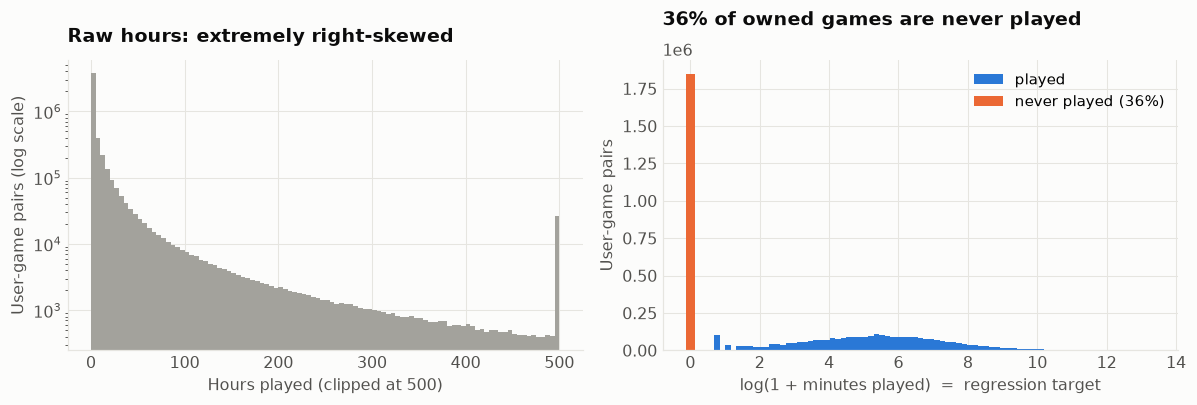

In [8]:
eda.playtime_hist(); plt.show()

The raw distribution is so skewed that MSE on raw minutes would be dominated by a few extreme pairs. After `log(1+x)`
the played pairs look roughly bell-shaped, **but a third of all mass sits exactly at zero**. That point mass is the
motivation for the **hurdle model** in Section 3: one stage for "did they start?", another for "how long?".

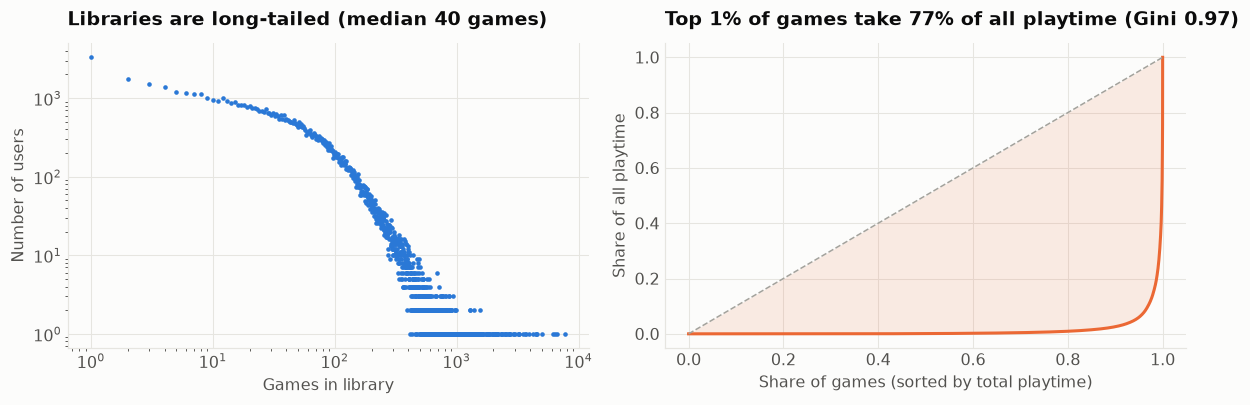

{'gini': np.float64(0.9739304510869954),
 'top1_share': np.float64(0.7668173178864727)}

In [9]:
fig, lt = eda.long_tail(); plt.show(); lt

Both users and games are long-tailed. A tiny fraction of games absorbs most playtime, so a **popularity baseline will be strong**,
and we must check whether our recommenders do anything beyond pushing hits (Section 4, popularity bias).

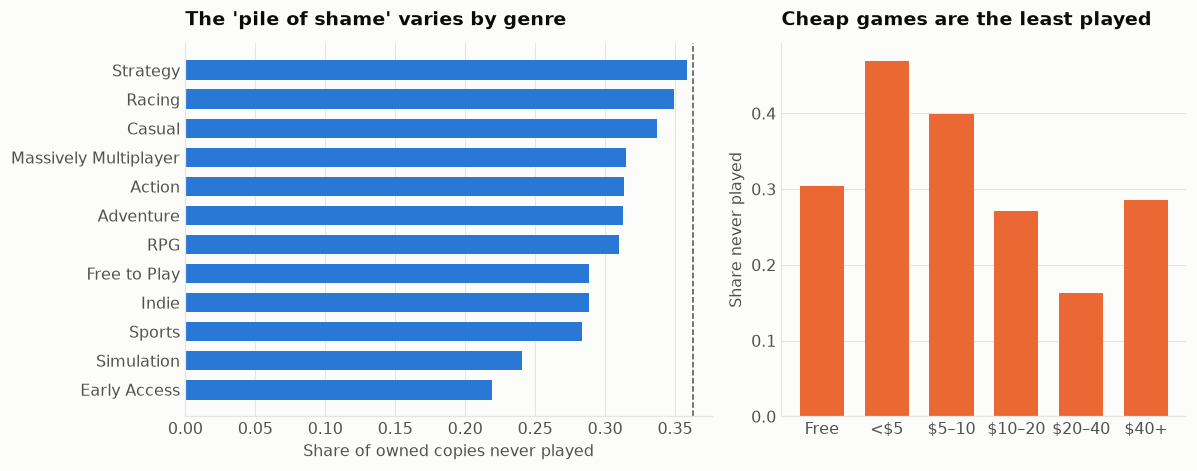

In [10]:
fig, by_genre, by_price = eda.pile_of_shame(); plt.show()

The "pile of shame" is not uniform. Cheap games (often bought in bundles or sales) are the least played, while expensive
games are usually played. Genre matters too. **Metadata carries signal about engagement**, which justifies the
metadata-aware models (factorization machine, LightGBM, content-based cold start).

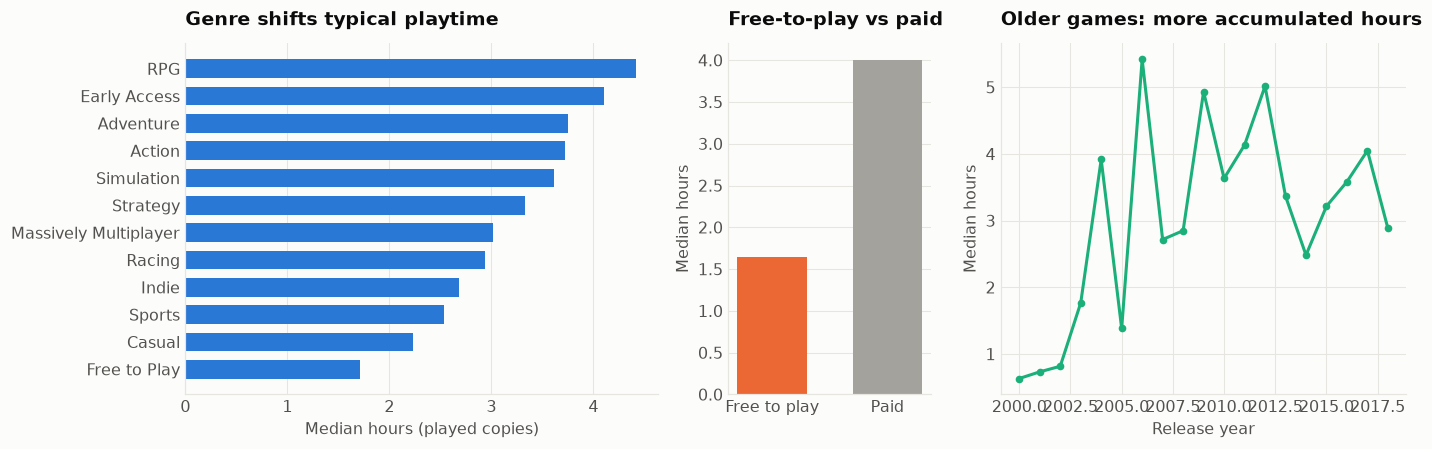

In [11]:
eda.metadata_signal(); plt.show()

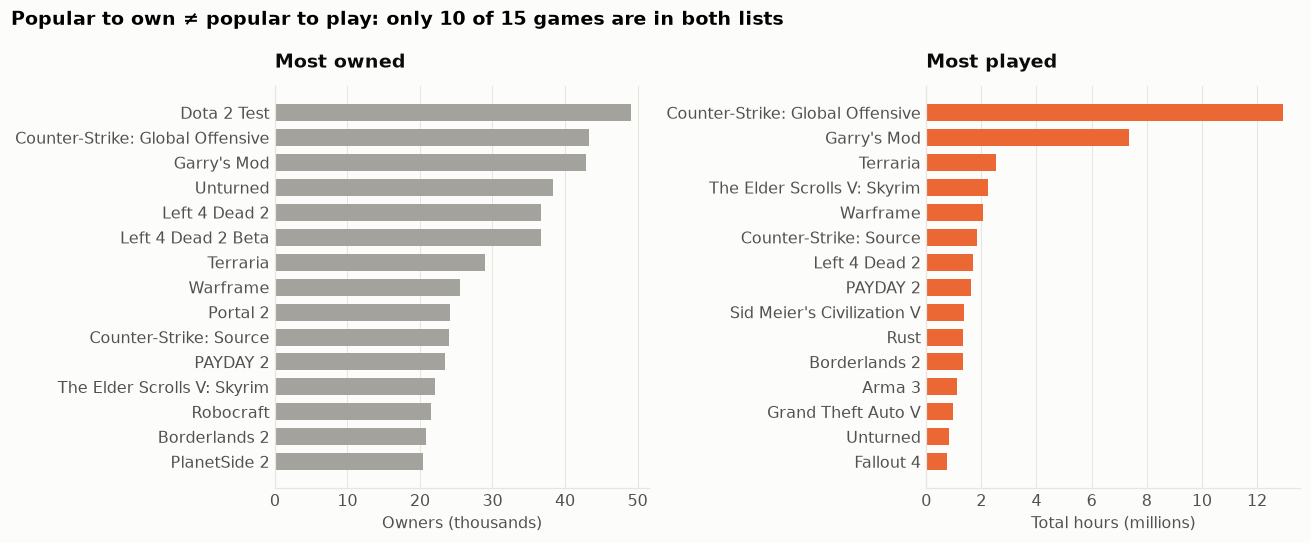

In [12]:
eda.own_vs_play(); plt.show()

Ownership and play diverge: free games and test builds (e.g. *Dota 2 Test*) are owned by everyone, while a few games
(CS:GO, Garry's Mod) absorb enormous hours. **A recommender trained on ownership alone would learn the wrong thing.**

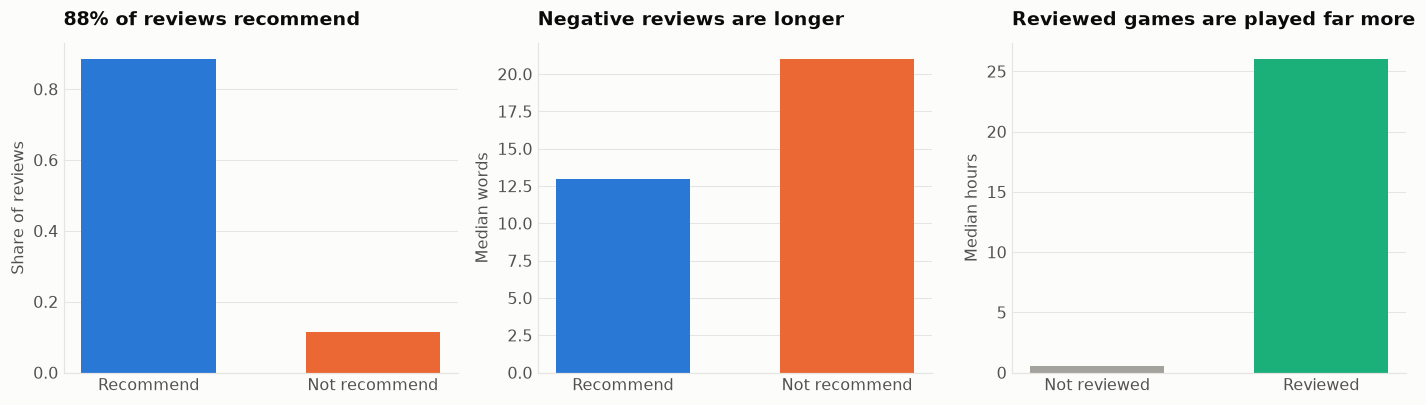

{'matched_reviews': 0.7562081771662302}

In [13]:
fig, rv = eda.reviews_view(); plt.show(); rv

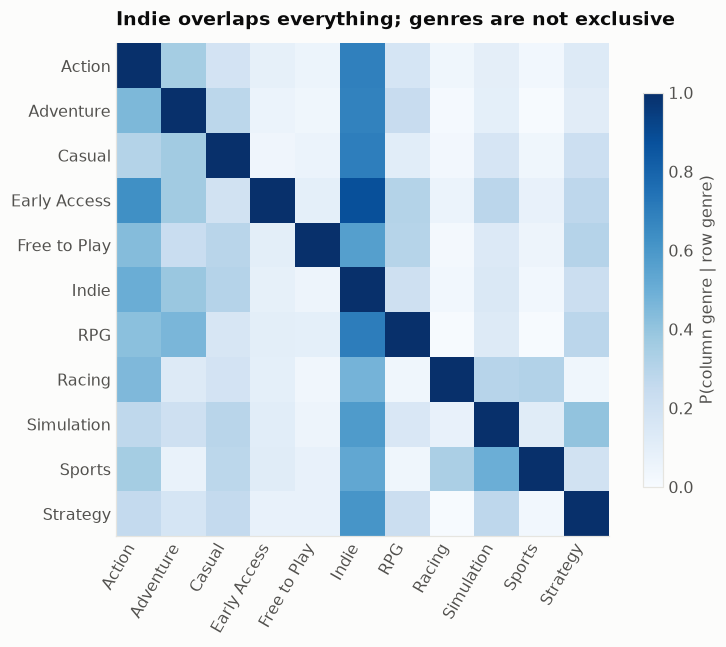

In [14]:
eda.genre_cooccurrence(); plt.show()

Reviews cover under 1.2% of pairs and are 88% positive, so they are too sparse and too skewed to be the main signal.
They confirm that reviewed games are heavily played. Genres overlap heavily (Indie co-occurs with most genres), so we
encode them as multi-hot features rather than a single category.

# 3. Modeling

### Formulation
| Task | Input | Output | Optimized |
|---|---|---|---|
| 3: hours | (user, game) in the user's library + metadata | ŷ ≈ log(1 + minutes) | squared error + L2 |
| 4: will play | same | P(played), P(active) | log-loss |
| 5: recommend | user's training history | a score per game; rank | ALS weighted squared loss / BPR pairwise loss / skip-gram |

Each model on the ladder adds **one idea** to the one before, so improvements can be attributed.

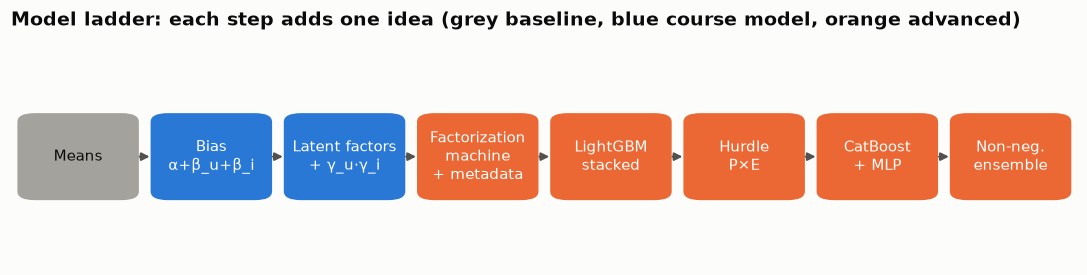

In [15]:
report.fig_ladder(); plt.show()

### 3.1 Bias model: `ŷ = α + β_u + β_i` (course week 4)
Fit by exact alternating updates. Each step solves its regularized least-squares subproblem in closed form, using `bincount`
over 3.8M rows (a few seconds). λ is tuned on `valid`.

In [16]:
show_code("steam/regression_cf.py", "BiasModel")

`steam/regression_cf.py` → `BiasModel`
```python
class BiasModel:
    """y ~ alpha + b_u + b_i with L2 penalty lam, fit by exact coordinate updates."""

    def __init__(self, lam=5.0, n_iter=15):
        self.lam, self.n_iter = lam, n_iter

    def fit(self, u, i, y, nu, ni):
        self.bu, self.bi = np.zeros(nu), np.zeros(ni)
        for _ in range(self.n_iter):
            self.alpha = np.mean(y - self.bu[u] - self.bi[i])
            r = y - self.alpha - self.bi[i]
            self.bu = np.bincount(u, r, nu) / (self.lam + np.bincount(u, minlength=nu))
            r = y - self.alpha - self.bu[u]
            self.bi = np.bincount(i, r, ni) / (self.lam + np.bincount(i, minlength=ni))
        return self

    def predict(self, u, i):
        return self.alpha + self.bu[u] + self.bi[i]
```

### 3.2 Latent factor model: `ŷ = α + β_u + β_i + γ_u·γ_i` (course week 4)
Implemented in PyTorch with minibatch Adam. L2 is applied only to the rows touched by each batch (the usual SGD
equivalent of the course objective). We grid-search K × λ on `valid` and keep the epoch with the best validation MSE.

**Overfitting diagnosis and fix.** Our first grid used λ ≤ 1e-3. The penalty is `λ · mean ‖row‖²` next to an MSE of about 4, so it was
roughly 1/4000 of the loss and changing λ barely moved validation MSE. MF memorized the training set: validation MSE was best at
epoch 2 (4.24) and climbed to 6.1 by epoch 12 while train MSE fell to 1.2. We widened the grid to λ ∈ {1e-3, 0.03, 0.1, 0.15, 0.2}
and K ∈ {32, 64, 128}. The best setting (K=128, λ=0.15) reaches valid MSE 4.138 and stays flat after its best epoch
(epoch 12: 4.142), and λ ≥ 0.2 starts to underfit. The stacked models below are rebuilt on these better MF scores.

In [17]:
show_code("steam/regression_cf.py", "MF", "_train_torch")

`steam/regression_cf.py` → `MF`
```python
class MF(torch.nn.Module):
    def __init__(self, nu, ni, k):
        super().__init__()
        self.P = torch.nn.Embedding(nu, k)
        self.Q = torch.nn.Embedding(ni, k)
        self.bu = torch.nn.Embedding(nu, 1)
        self.bi = torch.nn.Embedding(ni, 1)
        self.alpha = torch.nn.Parameter(torch.zeros(1))
        for e in (self.P, self.Q):
            torch.nn.init.normal_(e.weight, std=0.01)
        for e in (self.bu, self.bi):
            torch.nn.init.zeros_(e.weight)

    def forward(self, u, i):
        p, q = self.P(u), self.Q(i)
        pred = self.alpha + self.bu(u).squeeze(1) + self.bi(i).squeeze(1) + (p * q).sum(1)
        reg = (p ** 2).sum(1) + (q ** 2).sum(1) + self.bu(u).squeeze(1) ** 2 + self.bi(i).squeeze(1) ** 2
        return pred, reg

    def dot(self, u, i):
        return (self.P(u) * self.Q(i)).sum(1)
```

`steam/regression_cf.py` → `_train_torch`
```python
def _train_torch(model, fwd, tr, va, lam, epochs, lr=0.01, bs=32768, log=None):
    """Generic minibatch Adam loop with L2 on the rows touched by each batch.
    Keeps the epoch with the best validation MSE (early stopping)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ut, it = torch.from_numpy(tr.u.values.astype(np.int64)), torch.from_numpy(tr.i.values.astype(np.int64))
    yt = torch.from_numpy(tr.y.values.astype(np.float32))
    g = torch.Generator().manual_seed(SEED)
    best, best_state, hist = np.inf, None, []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(yt), generator=g)
        tot = 0.0
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            pred, reg = fwd(ut[b], it[b])
            loss = ((pred - yt[b]) ** 2).mean() + lam * reg.mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += ((pred.detach() - yt[b]) ** 2).sum().item()
        v = metrics.mse(va.y.values, _predict_torch(fwd, va))
        hist.append({"epoch": ep + 1, "train_mse": tot / len(yt), "valid_mse": v})
        if log:
            log(f"  epoch {ep + 1}: train {tot / len(yt):.4f}  valid {v:.4f}")
        if v < best:
            best, best_state = v, {k: x.clone() for k, x in model.state_dict().items()}
    model.load_state_dict(best_state)
    return hist
```

### 3.3 Factorization machine (Rendle 2010): adding metadata
An FM represents every feature (user id, game id, each genre, top tags, price/year/metascore buckets, free-to-play,
early access, the user's library-size bucket) with a weight and a latent vector, and models **all pairwise interactions**
in O(kn) with the identity `½[(Σ v x)² − Σ (v x)²]`. With only user and game ids it reduces exactly to the latent
factor model, so it is a strict generalization. For never-seen games the id feature is masked and the prediction
comes from metadata alone.

The FM had the same regularization-scale problem as MF (λ = 1e-4 was negligible). Its penalty sums over the ~20 active
feature vectors of each row, not two. Our first widened grid still put the best λ at its edge, and the FM training
curve kept overfitting after epoch 4, so we extended the search to λ ∈ {1e-4, 0.01, 0.03, 0.1, 0.2} and K ∈ {32, 64, 128}.

In [18]:
show_code("steam/regression_cf.py", "FM")

`steam/regression_cf.py` → `FM`
```python
class FM(torch.nn.Module):
    """Second-order factorization machine (Rendle 2010) over sparse feature lists.

    Each example is a padded list of (feature index, value). Fields: user id,
    user library-size bucket, item id, item genres, top tags, price / year /
    metascore buckets, free-to-play, early access.
    """

    def __init__(self, n_feat, k):
        super().__init__()
        self.w0 = torch.nn.Parameter(torch.zeros(1))
        self.w = torch.nn.Embedding(n_feat, 1)
        self.V = torch.nn.Embedding(n_feat, k)
        torch.nn.init.zeros_(self.w.weight)
        torch.nn.init.normal_(self.V.weight, std=0.01)

    def forward(self, idx, val):
        v = self.V(idx) * val.unsqueeze(-1)               # (B, L, k)
        linear = (self.w(idx).squeeze(-1) * val).sum(1)
        inter = 0.5 * ((v.sum(1) ** 2) - (v ** 2).sum(1)).sum(1)
        reg = (v ** 2).sum((1, 2))
        return self.w0 + linear + inter, reg
```

In [19]:
t = pd.DataFrame(report.load("regression_cf")["fm"]).sort_values("valid_mse")
display(Markdown(f"**FM validation grid** (best: K={t.iloc[0].K:.0f}, λ={t.iloc[0]['lambda']:g}, valid MSE {t.iloc[0].valid_mse:.4f}; "
                 f"weakest-λ setting from our first version: {t[t['lambda'] == 1e-4].valid_mse.min():.4f})"))
t.round(4)

**FM validation grid** (best: K=128, λ=0.1, valid MSE 4.2091; weakest-λ setting from our first version: 4.3113)

,K,lambda,valid_mse
5,128,0.1000,4.2091
4,64,0.2000,4.2113
3,64,0.1000,4.2138
2,64,0.0300,4.2324
1,32,0.0100,4.2873
0,32,0.0001,4.3113


### 3.4 Stacked LightGBM and 3.5 the hurdle model
Gradient boosting combines **leak-free engineered features** (user/game play rates and mean log-hours from `train`,
user × genre affinity, the share of the user's library in the game's genres, price, year, metascore, ...) with the
**outputs of 3.1–3.3**. It is trained on `valid` with 5-fold cross-fitting, so its training targets were never seen by the base models.

The **hurdle model** splits the problem in two. Since y = 0 whenever a game is unplayed,
`E[y] = P(played) · E[y | played]` is the MSE-optimal prediction. Stage 1 is exactly the Task 4 classifier.

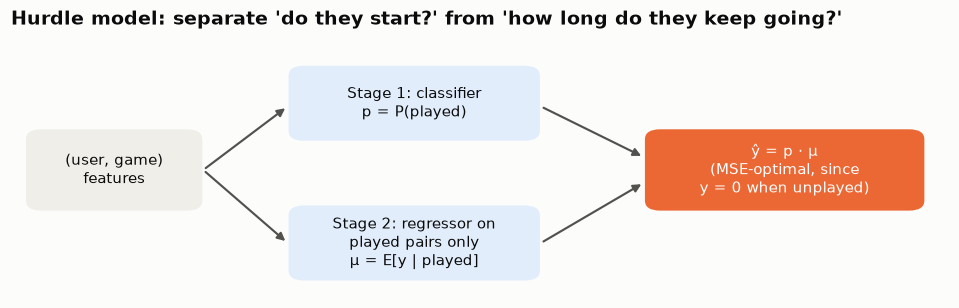

In [20]:
report.fig_hurdle(); plt.show()

#### Extra variables and explicit interactions
Our first version ignored several fields. All are now used, each with a leakage rule:

| Feature group | Columns | Leakage rule |
|---|---|---|
| Store **sentiment** (ordinal 0–8), few-review flag | `meta_sentiment`, `meta_few_store_reviews` | store metadata, no playtime |
| **Bundles**: number of bundles, max discount | `meta_n_bundles`, `meta_bundle_discount` | store metadata |
| **Developer / publisher** target encoding (mean log-hours, play rate, catalog size) | `meta_dev_*`, `meta_pub_*` | train playtime only, **leave-game-out**: a game's own hours are removed from its developer's average, otherwise a one-game developer's encoding *is* the game's mean, and the cold-start model would learn a signal it can never have for unseen games |
| **Reviews**: user's review count / recommend rate, game's review count / recommend rate | `user_n_reviews`, `item_n_reviews`, … | only reviews on **train** pairs (a review on a held-out pair would reveal that it was played) |
| Library composition: share of free games, mean price, share with metadata | `user_free_share`, `user_mean_price`, … | ownership is a legal input |
| **Interactions** | | |
| price relative to what this user usually owns | `x_price_vs_user` | |
| user × tag affinity (mean log-hours on games sharing the game's tags) | `ut_mean_y` | train playtime only |
| user × developer loyalty (hours on the developer's other games) | `udev_mean_y`, `udev_n` | train playtime only |
| **item-kNN regression**: similarity-weighted hours on the user's 20 most similar owned games, by **content** (works for unseen games) and by **item2vec** (warm only) | `uc_knn_*`, `cf_knn_*` | train playtime only; item2vec fit on train |

The cold-start model may only use columns with no game-identity signal (`user_`, `meta_`, `ug_`, `ut_`, `udev_`, `uc_`, `x_` prefixes).

In [21]:
show_code("steam/features.py", "item_extra", "_knn")

`steam/features.py` → `item_extra`
```python
def item_extra() -> pd.DataFrame:
    """Per-game metadata the first versions ignored + train-only developer/publisher/review encodings."""
    m = item_meta()
    _, _, reviews, bundles = data.load()
    tr = splits.load("train")
    ni = len(m)
    out = pd.DataFrame(index=np.arange(ni))
    sent = m.sentiment.astype("string")
    out["meta_sentiment"] = sent.map(SENTIMENT).astype(float).values
    n_small = sent.str.extract(r"^(\d+) user review")[0].astype(float)
    out["meta_few_store_reviews"] = n_small.values            # store page had < 10 reviews (else NaN)
    # bundles
    items = pd.read_parquet(ART / "item_index.parquet").reset_index().rename(columns={"index": "i"})
    b = bundles.merge(items, on="item_id")
    b["disc"] = pd.to_numeric(b.discount.astype(str).str.rstrip("%"), errors="coerce")
    out["meta_n_bundles"] = b.groupby("i").size().reindex(out.index).fillna(0).values
    out["meta_bundle_discount"] = b.groupby("i").disc.max().reindex(out.index).values
    # developer / publisher target encoding (smoothed, train playtime only), LEAVE-GAME-OUT:
    # a game's own playtime is subtracted from its developer's totals. Otherwise a one-game developer's
    # encoding equals the game's own mean, and the cold-start model (trained on warm games) would learn
    # to trust a signal that can never contain the game itself for never-seen games.
    gmean, k = tr.y.mean(), 20.0
    own = pd.DataFrame({"i": tr.i.values, "y": tr.y.values, "p": tr.played.values}).groupby("i").agg(
        s=("y", "sum"), n=("y", "size"), ps=("p", "sum")).reindex(out.index).fillna(0)
    for col in ["developer", "publisher"]:
        key = m[col].map(_first)
        g = own.groupby(key.values).sum()               # per developer: sum y, count, sum played
        tot = g.reindex(key.values).set_axis(out.index)
        s_, n_, ps_ = tot.s - own.s, tot.n - own.n, tot.ps - own.ps
        short = col[:3]
        out[f"meta_{short}_mean_y"] = np.where(key.notna(), (s_ + k * gmean) / (n_ + k), np.nan)
        out[f"meta_{short}_played_rate"] = np.where(key.notna() & (n_ > 0), ps_ / np.maximum(n_, 1), np.nan)
        out[f"meta_{short}_n_games"] = key.map(key.value_counts()).astype(float).values
    # reviews written on TRAIN pairs only (a review on a held-out pair would reveal that it was played)
    rv = _reviews_train()
    out["item_n_reviews"] = rv.groupby("i").size().reindex(out.index).fillna(0).values
    out["item_recommend_rate"] = rv.groupby("i").recommend.mean().reindex(out.index).values
    return out
```

`steam/features.py` → `_knn`
```python
def _knn(df, V, k=20):
    """Similarity-weighted average of the user's own train log-playtime over the k most similar
    games they own (item-based CF with learned or content similarity). Returns knn_y, knn_played, max_sim."""
    tr = splits.load("train").sort_values("u")
    ui = np.searchsorted(tr.u.values, np.arange(splits.stats()["n_users"] + 1))
    ti, ty, tp = tr.i.values, tr.y.values, tr.played.values.astype(float)
    out = np.full((len(df), 3), np.nan)
    order = np.argsort(df.u.values, kind="stable")
    du, di = df.u.values[order], df.i.values[order]
    bounds = np.flatnonzero(np.diff(du)) + 1
    sparse_V = sp.issparse(V)
    for grp in np.split(np.arange(len(du)), bounds):
        u = du[grp[0]]
        a, b = ui[u], ui[u + 1]
        if b - a == 0:
            continue
        J, T = ti[a:b], di[grp]
        Sm = (V[T] @ V[J].T).toarray() if sparse_V else V[T] @ V[J].T
        Sm = np.maximum(Sm, 0)
        if Sm.shape[1] > k:
            thr = -np.partition(-Sm, k - 1, axis=1)[:, k - 1:k]
            Sm = np.where(Sm >= thr, Sm, 0)
        w = Sm.sum(1)
        ok = w > 1e-9
        res = np.full((len(T), 3), np.nan)
        res[ok, 0] = (Sm[ok] @ ty[a:b]) / w[ok]
        res[ok, 1] = (Sm[ok] @ tp[a:b]) / w[ok]
        res[:, 2] = Sm.max(1)
        out[order[grp]] = res
    return out
```

In [22]:
show_code("steam/regression_stack.py", "_es_split", "crossfit_lgb", "run")

`steam/regression_stack.py` → `_es_split`
```python
def _es_split(a, frac=0.1, seed=SEED):
    """Early-stopping slice carved out of the TRAINING fold, so the out-of-fold rows never
    choose the number of trees (choosing it on the scored fold would leak and flatter OOF MSE)."""
    es = np.random.default_rng(seed).random(len(a)) < frac
    return a[~es], a[es]
```

`steam/regression_stack.py` → `crossfit_lgb`
```python
def crossfit_lgb(X_va, y_va, X_others, params, n_rounds=2000, folds=5, name=None):
    """K-fold cross-fitting on VALID: OOF predictions for valid, fold-average for others."""
    oof = np.zeros(len(X_va))
    others = [np.zeros(len(X)) for X in X_others]
    models, tr_err = [], []
    for a, b in KFold(folds, shuffle=True, random_state=SEED).split(X_va):
        fit, es = _es_split(a)
        bst = lgb.train(params, lgb.Dataset(X_va.iloc[fit], y_va[fit]), n_rounds,
                        valid_sets=[lgb.Dataset(X_va.iloc[es], y_va[es])],
                        callbacks=[lgb.early_stopping(50, verbose=False)])
        oof[b] = bst.predict(X_va.iloc[b], num_iteration=bst.best_iteration)
        for o, X in zip(others, X_others):
            o += bst.predict(X, num_iteration=bst.best_iteration) / folds
        models.append(bst)
        if name and params.get("objective") == "regression":
            tr_err.append(metrics.mse(y_va[fit], bst.predict(X_va.iloc[fit], num_iteration=bst.best_iteration)))
    if tr_err:
        FIT_GAP[name] = {"train_mse": float(np.mean(tr_err)), "oof_mse": metrics.mse(y_va, oof),
                         "rounds": float(np.mean([m.best_iteration for m in models]))}
    return oof, others, models
```

`steam/regression_stack.py` → `run`
```python
def run(log=print):
    t0 = time.time()
    sets = {n: splits.load(n) for n in ["valid", "test", "cold"]}
    va = sets["valid"]
    preds = {n: pd.read_parquet(ART / f"reg_base_{n}.parquet") for n in sets}
    Xs = {n: stack_features(n, d, preds[n]) for n, d in sets.items()}
    log(f"[3.4] features: {Xs['valid'].shape[1]} columns ({time.time() - t0:.0f}s)")

    # ---- 3.4 LightGBM on stacked features
    oof, (p_te, p_co), models = crossfit_lgb(Xs["valid"], va.y.values, [Xs["test"], Xs["cold"]], LGB_REG,
                                             name="LightGBM (stacked)")
    for n, p in zip(sets, [oof, p_te, p_co]):
        preds[n]["LightGBM (stacked)"] = p
    imp = pd.Series(np.mean([m.feature_importance("gain") for m in models], 0), index=Xs["valid"].columns)
    imp.sort_values(ascending=False).to_json(RES / "lgb_importance.json")
    log(f"[3.4] LightGBM OOF MSE {metrics.mse(va.y.values, oof):.4f} ({time.time() - t0:.0f}s)")

    # ---- 3.4b cold-safe LightGBM: no game-identity signal (no item stats, no CF outputs).
    # The only model that can legitimately score never-seen games; also the
    # "remove collaborative features" ablation on warm games.
    meta_cols = [c for c in Xs["valid"].columns if c.startswith(features.META_PREFIXES)]
    oof_m, (te_m, co_m), _ = crossfit_lgb(Xs["valid"][meta_cols], va.y.values,
                                          [Xs["test"][meta_cols], Xs["cold"][meta_cols]], LGB_REG,
                                          name="LightGBM (metadata only)")
    for n, p in zip(sets, [oof_m, te_m, co_m]):
        preds[n]["LightGBM (metadata only)"] = p
    log(f"[3.4b] metadata-only LightGBM OOF MSE {metrics.mse(va.y.values, oof_m):.4f} ({time.time() - t0:.0f}s)")

    # ---- 3.5 hurdle: P(played) x E[y | played]
    # MSE-optimal prediction is E[y] = P(played) * E[y | played] because y = 0 when unplayed.
    oof_p, (te_p, co_p), clf_models = crossfit_lgb(Xs["valid"], va.played.values, [Xs["test"], Xs["cold"]], LGB_CLF)
    pl = va.played.values == 1
    oof_mu, (va_mu, te_mu, co_mu), _ = crossfit_lgb(Xs["valid"][pl].reset_index(drop=True), va.y.values[pl],
                                                  [Xs["valid"], Xs["test"], Xs["cold"]], LGB_REG,
                                                  name="Hurdle stage 2 (played only)")
    va_mu = va_mu.copy()
    va_mu[pl] = oof_mu                       # out-of-fold wherever the row trained stage 2
    for n, p, mu in zip(sets, [oof_p, te_p, co_p], [va_mu, te_mu, co_mu]):
        preds[n]["Hurdle (LightGBM)"] = p * mu
    np.savez(ART / "played_probs_lgb.npz", valid=oof_p, test=te_p, cold=co_p)
    log(f"[3.5] hurdle OOF MSE {metrics.mse(va.y.values, preds['valid']['Hurdle (LightGBM)']):.4f} ({time.time() - t0:.0f}s)")

    # ---- 3.7 other nonlinear learners: CatBoost (here) and an MLP (regression_nn.py, torch process)
    oof_c, (te_c, co_c) = crossfit_catboost(Xs["valid"], va.y.values, [Xs["test"], Xs["cold"]])
    for n, p in zip(sets, [oof_c, te_c, co_c]):
        preds[n]["CatBoost (stacked)"] = p
    log(f"[3.7] CatBoost OOF MSE {metrics.mse(va.y.values, oof_c):.4f} ({time.time() - t0:.0f}s)")
    has_nn = (ART / "reg_nn_valid.parquet").exists()
    if has_nn:
        for n in sets:
            preds[n]["MLP (neural net)"] = pd.read_parquet(ART / f"reg_nn_{n}.parquet")["MLP (neural net)"].values
        log(f"[3.7] MLP OOF MSE {metrics.mse(va.y.values, preds['valid']['MLP (neural net)']):.4f}")

    # ---- 3.6 ensemble: NON-NEGATIVE blend fit on valid OOF predictions (no offsetting weights)
    base = ["Bias model", "Latent factor (MF)", "Factorization machine", "LightGBM (stacked)", "Hurdle (LightGBM)",
            "CatBoost (stacked)"] + (["MLP (neural net)"] if has_nn else [])
    A = np.column_stack([preds["valid"][base].values, np.ones(len(va))])
    w, _ = nnls(A, va.y.values)
    for n in sets:
        preds[n]["Ensemble"] = np.column_stack([preds[n][base].values, np.ones(len(preds[n]))]) @ w
    tuning = {"blend_weights": dict(zip(base, w[:-1].tolist())), "blend_intercept": float(w[-1]),
              "fit_gap": FIT_GAP}
    log(f"[3.6] blend weights {tuning['blend_weights']}")
    log(f"[3.6] fit gaps {FIT_GAP}")

    results = {}
    for n, d in sets.items():
        P = preds[n].drop(columns=[c for c in preds[n].columns if c.startswith("_")])
        results[n] = {m: metrics.regression_report(d.y.values, P[m].values) for m in P.columns}
        if n != "valid":
            P.astype(np.float32).to_parquet(ART / f"reg_preds_{n}.parquet")
    with open(RES / "regression.json", "w") as f:
        json.dump({"results": results, "tuning": tuning}, f, indent=1)
    log(f"[3B] done in {time.time() - t0:.0f}s")
    return results
```

#### 3.7 Other nonlinear learners: CatBoost and a neural network
- **CatBoost** (ordered boosting on symmetric trees) is a different tree learner from LightGBM (leaf-wise trees): it is
  more resistant to overfitting on target-like features and its errors are only partly correlated with LightGBM's.
- **MLP (PyTorch)**, 3 hidden layers (256-128-64, ReLU, dropout), on the same stacked features after log-compression,
  median imputation with missing-value indicators, and standardization (all fit on the training fold only). A neural
  network learns smooth interactions among all features at once rather than axis-aligned splits.
- All learners use the **same 5 folds** on `valid`, so their out-of-fold predictions can be blended without leakage.
  The final **ensemble** is a **non-negative** least-squares blend of the out-of-fold predictions (no offsetting
  positive/negative weights that only fit noise).

**Early stopping without leakage.** Our first version early-stopped LightGBM on the very fold it then scored, so the
out-of-fold rows chose the number of trees (a mild optimistic bias). Every learner now early-stops on a 10% slice carved
out of its *training* fold.

In [23]:
show_code("steam/regression_stack.py", "crossfit_catboost")

`steam/regression_stack.py` → `crossfit_catboost`
```python
def crossfit_catboost(X_va, y_va, X_others, folds=5, name="CatBoost"):
    """Same protocol with CatBoost (ordered boosting on symmetric trees): a different tree learner."""
    oof = np.zeros(len(X_va))
    others = [np.zeros(len(X)) for X in X_others]
    tr_err, its = [], []
    for a, b in KFold(folds, shuffle=True, random_state=SEED).split(X_va):
        fit, es = _es_split(a)
        m = CatBoostRegressor(iterations=3000, learning_rate=0.08, depth=8, l2_leaf_reg=3, loss_function="RMSE",
                              random_seed=SEED, thread_count=8, verbose=0, od_type="Iter", od_wait=100)
        m.fit(X_va.iloc[fit], y_va[fit], eval_set=(X_va.iloc[es], y_va[es]), use_best_model=True)
        oof[b] = m.predict(X_va.iloc[b])
        for o, X in zip(others, X_others):
            o += m.predict(X) / folds
        tr_err.append(metrics.mse(y_va[fit], m.predict(X_va.iloc[fit])))
        its.append(m.get_best_iteration())
    FIT_GAP[name] = {"train_mse": float(np.mean(tr_err)), "oof_mse": metrics.mse(y_va, oof), "rounds": float(np.mean(its))}
    return oof, others
```

In [24]:
show_code("steam/regression_nn.py", "MLP", "fit_mlp")

`steam/regression_nn.py` → `MLP`
```python
class MLP(torch.nn.Module):
    def __init__(self, d, hidden=(256, 128, 64), drop=0.1):
        super().__init__()
        layers, prev = [], d
        for h in hidden:
            layers += [torch.nn.Linear(prev, h), torch.nn.ReLU(), torch.nn.Dropout(drop)]
            prev = h
        layers.append(torch.nn.Linear(prev, 1))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)
```

`steam/regression_nn.py` → `fit_mlp`
```python
def fit_mlp(Xtr, ytr, Xes, yes, epochs=40, lr=1e-3, wd=1e-5, bs=2048, patience=4, seed=SEED, log=None):
    """Adam on MSE; early stopping on a held-out slice (Xes, yes). Returns the best model + history."""
    torch.manual_seed(seed)
    m = MLP(Xtr.shape[1])
    with torch.no_grad():
        m.net[-1].bias.fill_(float(ytr.mean()))
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=1)
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.float32))
    Xe = torch.from_numpy(Xes)
    g = torch.Generator().manual_seed(seed)
    best, state, bad, hist = np.inf, None, 0, []
    for ep in range(epochs):
        m.train()
        perm = torch.randperm(len(yt), generator=g)
        tot = 0.0
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            loss = ((m(Xt[b]) - yt[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(b)
        m.eval()
        with torch.no_grad():
            v = metrics.mse(yes, m(Xe).numpy())
        sched.step(v)
        hist.append({"epoch": ep + 1, "train_mse": tot / len(yt), "es_mse": v})
        if v < best - 1e-4:
            best, state, bad = v, {k: x.clone() for k, x in m.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state)
    m.eval()
    return m, hist
```

### 3.6 Recommendation models (Task 5)
- **Most-popular / Jaccard item-kNN**: course baselines; Jaccard over sets of players, summed over the user's games.
- **BPR-MF** (Rendle 2009): pairwise loss, played > not played.
- **Implicit ALS** (Hu, Koren & Volinsky 2008): *played* is a preference with confidence `1 + α·c`. We compare
  `c = 1` (**binary**) with `c = log(1 + minutes)` (**playtime-weighted**), which uses *how much*, not just *whether*.
- **item2vec**: skip-gram over each user's games sorted by playtime (as in HW4); user = playtime-weighted mean vector.
- **Content**: tf-idf over tags, genres, specs and developer; the user profile is a playtime-weighted mean.
- **Cold start**: a ridge map from content to ALS item factors, learned on warm games and applied to unseen ones.
- **Hybrid**: ALS + content, blended on **per-user z-scores** (rank-normalizing, as in our first version, threw away score gaps
  and made the hybrid *worse* than ALS); the content weight is tuned on `valid`.
- **Learning-to-rank reranker (LightGBM LambdaRank; Burges 2010)**: each candidate gets every base model's score, its per-user
  z-score, and game metadata, and LambdaRank learns how to combine them by directly optimizing NDCG. It is trained on the
  `valid` protocol and evaluated on `test`/`hard`, which hold different held-out games; the base models only saw `train`.
- **Task 4 → Task 5:** the hard protocol (played vs owned-but-unplayed) *is* the "will they play it?" question asked per user,
  so we also rank it with the LightGBM played-classifier from Section 3.5.

Hyperparameters tuned on `valid`: ALS confidence α, factors and L2; BPR factors, learning rate, L2 and epochs; hybrid weight.

In [25]:
show_code("steam/ranking.py", "fit_als", "fit_item2vec", "mapped_factor_scorer", "zscore_rows")

`steam/ranking.py` → `fit_als`
```python
def fit_als(M, factors=64, reg=0.05, alpha=20.0, iters=15, seed=SEED):
    m = AlternatingLeastSquares(factors=factors, regularization=reg, alpha=alpha,
                                iterations=iters, random_state=seed)
    m.fit(M, show_progress=False)
    return m.user_factors, m.item_factors
```

`steam/ranking.py` → `fit_item2vec`
```python
def fit_item2vec(W, dim=64, window=10, epochs=10, seed=SEED):
    """Each user's played games, sorted by playtime (desc), form a 'sentence'."""
    W = W.tocsr()
    sents = []
    for u in range(W.shape[0]):
        a, b = W.indptr[u], W.indptr[u + 1]
        if b - a >= 2:
            order = np.argsort(-W.data[a:b])
            sents.append([str(x) for x in W.indices[a:b][order]])
    w2v = Word2Vec(sents, vector_size=dim, window=window, min_count=1, sg=1, negative=10,
                   epochs=epochs, workers=8, seed=seed)
    V = np.zeros((W.shape[1], dim), np.float32)
    for tok in w2v.wv.index_to_key:
        V[int(tok)] = w2v.wv[tok]
    V = normalize(V)
    U = normalize(W @ V)                    # playtime-weighted average of game vectors
    return U, V
```

`steam/ranking.py` → `mapped_factor_scorer`
```python
def mapped_factor_scorer(U, V, X, warm_items, alpha=1.0):
    """Cold start: learn a ridge map from content to ALS item factors on warm games,
    then give never-seen games a factor vector predicted from their content."""
    ridge = Ridge(alpha=alpha).fit(X[warm_items], V[warm_items])
    V_hat = V.copy()
    V_hat[:] = ridge.predict(X)
    return factor_scorer(U, V_hat), V_hat
```

`steam/ranking.py` → `zscore_rows`
```python
def zscore_rows(S):
    """Per-user standardization: keeps score gaps (rank-normalizing throws them away)."""
    S = np.asarray(S, np.float64)
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)
```

In [26]:
show_code("steam/ranking_ltr.py", "candidate_features", "run")

`steam/ranking_ltr.py` → `candidate_features`
```python
def candidate_features(z):
    """(n_users * n_cands, n_features) matrix + names, from a rank_feats_*.npz file."""
    F, cands, users = z["F"].astype(np.float64), z["cands"], z["users"]
    names = [str(n) for n in z["names"]]
    n, c, k = F.shape
    Z = (F - F.mean(1, keepdims=True)) / (F.std(1, keepdims=True) + 1e-9)    # per-user z-scores
    m = features.item_meta()
    ustats = features.train_stats()[0]
    meta = np.stack([m.price.values, m.release_year.values, m.metascore.values,
                     m.free.values, m.early_access.values, m.n_specs.values], 1).astype(np.float64)
    cols = [F.reshape(-1, k), Z.reshape(-1, k), meta[cands.ravel()],
            np.repeat(ustats.n_train.values[users], c)[:, None].astype(np.float64)]
    names = names + [f"z: {x}" for x in names] + ["meta_price", "meta_release_year", "meta_metascore",
                                                  "meta_free", "meta_early_access", "meta_n_specs",
                                                  "user_n_train"]
    return pd.DataFrame(np.hstack(cols), columns=names), (n, c)
```

`steam/ranking_ltr.py` → `run`
```python
def run(log=print):
    t0 = time.time()
    Z = {p: np.load(ART / f"rank_feats_{p}.npz") for p in ["valid", "test", "hard"]}
    X = {p: candidate_features(z) for p, z in Z.items()}
    results = {"test": {}, "hard": {}}

    # ---- 5.5 LambdaRank: train on valid users (10% of them held out for early stopping)
    Xv, (n, c) = X["valid"]
    y = np.zeros((n, c)); y[:, 0] = 1
    rng = np.random.default_rng(SEED)
    hold = rng.random(n) < 0.1
    rows = lambda mask: np.repeat(mask, c)
    dtr = lgb.Dataset(safe(Xv[rows(~hold)]), y[~hold].ravel(), group=np.full((~hold).sum(), c))
    dva = lgb.Dataset(safe(Xv[rows(hold)]), y[hold].ravel(), group=np.full(hold.sum(), c))
    # LightGBM's built-in NDCG breaks ties optimistically, so an untrained model (all scores tied)
    # looks perfect and early-stops at round 1. Use our pessimistic-tie NDCG@10 instead.
    def feval(pred, ds):
        return "ndcg10_pessimistic", float(user_ndcg(pred.reshape(-1, c)).mean()), True
    bst = lgb.train(LTR, dtr, 2000, valid_sets=[dva], feval=feval,
                    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(100)])
    log(f"[5.5] LambdaRank: {bst.best_iteration} rounds, held-out valid NDCG@10 "
        f"{bst.best_score['valid_0']['ndcg10_pessimistic']:.4f} ({time.time() - t0:.0f}s)")
    for p in ["test", "hard"]:
        Xp, (n_p, c_p) = X[p]
        S = bst.predict(safe(Xp), num_iteration=bst.best_iteration).reshape(n_p, c_p)
        results[p]["LTR reranker (LightGBM)"] = metrics.ranking_report(
            S[:, 0], S[:, 1:], ks=(1, 3) if c_p < 20 else (1, 10))
        log(f"[5.5] {p}: {results[p]['LTR reranker (LightGBM)']}")
    imp = pd.Series(bst.feature_importance("gain"), index=Xv.columns).sort_values(ascending=False)

    # paired bootstrap over test users: is the reranker's gain over each base model real?
    Xt, (n_t, c_t) = X["test"]
    S_ltr = bst.predict(safe(Xt), num_iteration=bst.best_iteration).reshape(n_t, c_t)
    base_scores = {str(nm): Z["test"]["F"][:, :, k] for k, nm in enumerate(Z["test"]["names"])}
    paired = {nm: paired_bootstrap(user_ndcg(S_ltr), user_ndcg(S)) for nm, S in base_scores.items()}
    log(f"[5.5] paired bootstrap (LTR minus base, NDCG@10): "
        + ", ".join(f"{k}: {v['diff']:+.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}]" for k, v in paired.items()))

    # ---- 5.6 the Task 4 played-classifier on the hard protocol (all candidates are test pairs)
    te = splits.load("test")
    prob = np.load(ART / "played_probs_lgb.npz")["test"]
    lookup = pd.Series(prob, index=pd.MultiIndex.from_arrays([te.u.values, te.i.values]))
    zh = Z["hard"]
    users, cands = zh["users"], zh["cands"]
    S = lookup.reindex(pd.MultiIndex.from_arrays([np.repeat(users, cands.shape[1]), cands.ravel()])).values
    assert not np.isnan(S).any(), "every hard candidate should be a test pair"
    S = S.reshape(cands.shape)
    results["hard"]["Played classifier (Task 4 LightGBM)"] = metrics.ranking_report(S[:, 0], S[:, 1:], ks=(1, 3))
    log(f"[5.6] hard, played classifier: {results['hard']['Played classifier (Task 4 LightGBM)']}")

    with open(RES / "ranking_ltr.json", "w") as f:
        json.dump({"results": results, "importance": imp.to_dict(), "rounds": int(bst.best_iteration),
                   "paired_ndcg10_test": paired}, f, indent=1)
    log(f"[5.5] done in {time.time() - t0:.0f}s")
    return results
```

### What the models learn

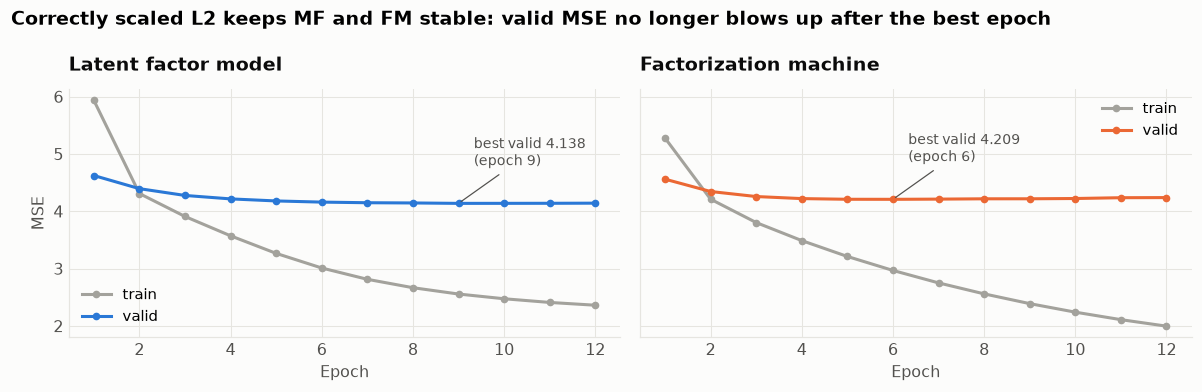

In [27]:
report.fig_training_curves(); plt.show()

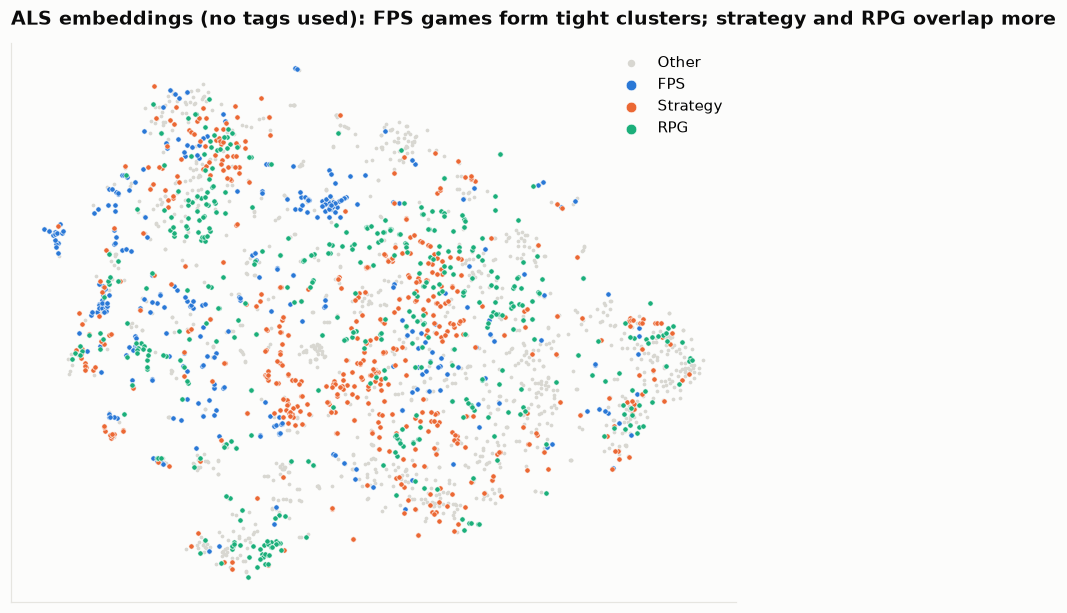

In [28]:
report.fig_tsne(); plt.show()

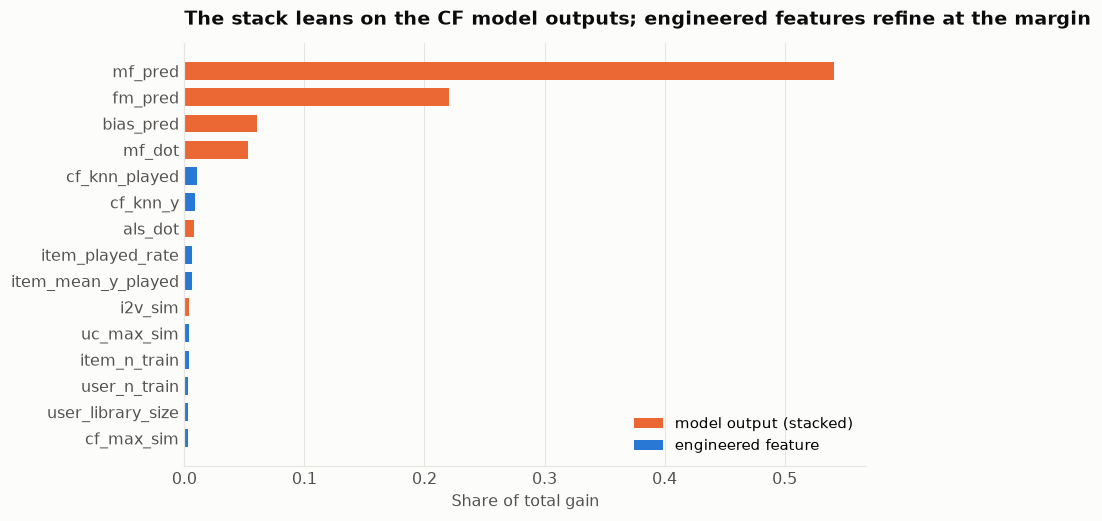

In [29]:
report.fig_importance(); plt.show()

### Trade-offs between approaches
| Model | Strengths | Weaknesses | Cost here |
|---|---|---|---|
| Bias model | interpretable, closed form, strong baseline | no personalization beyond offsets | seconds |
| Latent factors | personal taste; embeddings reusable for ranking | cannot score unseen games; needs tuning | ~1 min per config |
| Factorization machine | adds metadata, handles cold start, generalizes MF | more hyperparameters; sparse-feature engineering | ~2 min per config |
| LightGBM stack | strongest tabular learner, feature importance | needs careful out-of-fold protocol to avoid leakage | ~1 min |
| Hurdle | matches the zero-inflated target; reuses the Task 4 classifier | two models to maintain | ~2 min |
| CatBoost | robust to overfitting, different inductive bias from LightGBM | slower to train | ~5 min |
| MLP | smooth feature interactions; complements trees in a blend | needs scaling/imputation; less interpretable | ~3 min |
| ALS (implicit) | fast, uses playtime as confidence | squared loss on 0/1 targets; popularity-leaning | ~10 s per config |
| BPR | optimizes ranking directly | slow to converge; sensitive to learning rate | ~1 min |
| Content / mapped factors | only option for unseen games | weaker on warm games | seconds |
| LambdaRank reranker | combines complementary signals; optimizes NDCG directly | needs every base model at serving time; needs its own held-out data | ~2 min |

# 4. Evaluation

The evaluation code is one shared module, so every model is scored the same way. Ranking ties are broken
**pessimistically**, so a constant scorer cannot look good. Error bars for the factor models come from 3 random seeds.

In [30]:
show_code("steam/metrics.py", "ranking_report", "ber", "beyond_accuracy")

`steam/metrics.py` → `ber`
```python
def ber(y, p_hat, thr=0.5):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(p_hat) >= thr
    fpr = np.mean(pred[~y]) if (~y).any() else 0.0
    fnr = np.mean(~pred[y]) if y.any() else 0.0
    return float(0.5 * (fpr + fnr))
```

`steam/metrics.py` → `ranking_report`
```python
def ranking_report(pos_scores, neg_scores, ks=(1, 10)):
    """Leave-one-out style metrics.

    pos_scores: (n_users,) score of the held-out positive
    neg_scores: (n_users, n_neg) scores of that user's sampled negatives
    Ties are broken pessimistically (a tie counts as ranked above the positive)
    so a constant scorer cannot look good.
    """
    pos = np.asarray(pos_scores, dtype=np.float64)[:, None]
    neg = np.asarray(neg_scores, dtype=np.float64)
    rank = (neg >= pos).sum(1)                  # 0 = positive ranked first
    n_neg = neg.shape[1]
    auc = 1.0 - ((neg > pos).sum(1) + 0.5 * (neg == pos).sum(1)) / n_neg
    out = {"AUC": float(auc.mean())}
    for k in ks:
        hit = rank < k
        out[f"HR@{k}"] = float(hit.mean())
        out[f"NDCG@{k}"] = float(np.where(hit, 1.0 / np.log2(rank + 2), 0.0).mean())
    return out
```

`steam/metrics.py` → `beyond_accuracy`
```python
def beyond_accuracy(topk: np.ndarray, item_pop: np.ndarray, n_items: int, head_frac=0.01):
    """Catalog coverage, head share and novelty for a matrix of top-K recommendations.

    topk:     (n_users, K) recommended item indices
    item_pop: (n_items,) training popularity (number of players)
    """
    flat = topk.ravel()
    order = np.argsort(-item_pop)
    head = np.zeros(n_items, bool)
    head[order[: max(1, int(head_frac * n_items))]] = True
    p = (item_pop + 1) / (item_pop.sum() + n_items)
    return {"coverage": float(len(np.unique(flat)) / n_items),
            "head_share": float(head[flat].mean()),
            "novelty": float(np.mean(-np.log2(p[flat])))}
```

## 4.1 Main task: hours played (regression)

In [31]:
reg = report.table_regression("test")
display(report.style_table(reg, best_low=["MSE", "MAE"], fmt="{:.4f}"))
b = reg.MSE.idxmin()
display(Markdown(f"**Best: {b}**, test MSE **{reg.loc[b,'MSE']:.3f}** vs **{reg.loc['Global mean','MSE']:.3f}** "
                 f"for the global mean (**{reg.loc[b,'vs global mean']:.0%} lower**) and "
                 f"{reg.loc['Bias model','MSE']:.3f} for the course bias model."))

,MSE,MAE,vs global mean
Global mean,9.1240,2.7095,0.0000
User mean,8.0579,2.4304,0.1168
Item mean,5.3956,1.8557,0.4086
Bias model,4.7741,1.7412,0.4768
Latent factor (MF),4.1504,1.5921,0.5451
Factorization machine,4.2181,1.5672,0.5377
LightGBM (stacked),3.8617,1.4494,0.5768
LightGBM (metadata only),5.0802,1.7925,0.4432
Hurdle (LightGBM),3.8585,1.4436,0.5771
CatBoost (stacked),3.8650,1.4523,0.5764


**Best: Ensemble**, test MSE **3.853** vs **9.124** for the global mean (**58% lower**) and 4.774 for the course bias model.

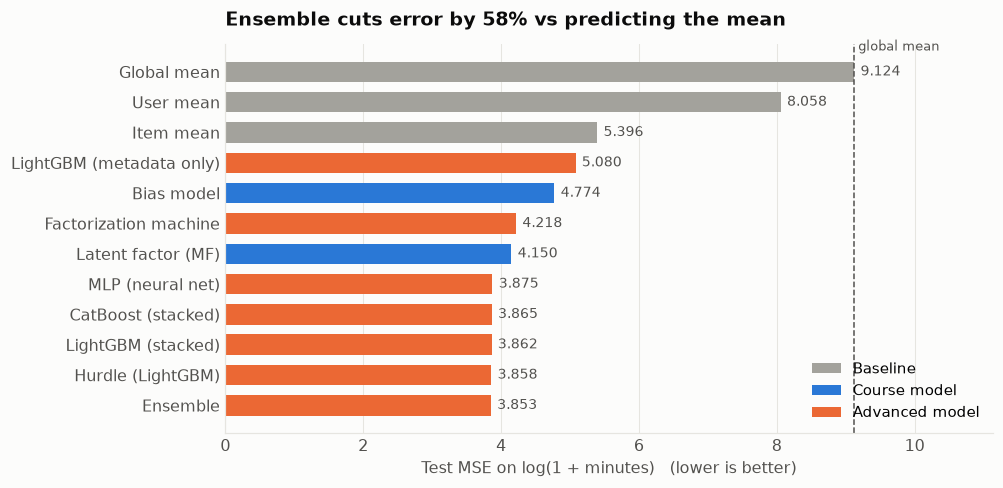

In [32]:
report.fig_mse_bars("test"); plt.show()

**Overfitting check.** For every cross-fit learner: mean in-fold training MSE vs out-of-fold MSE, and the number of
trees/epochs chosen by early stopping. A small gap means the learner generalizes; a large one means it memorized.

In [33]:
report.table_fit_gap().round(4)

,train_mse,oof_mse,trees / epochs,gap (oof − train)
LightGBM (stacked),3.4519,3.8644,594.2,0.4126
LightGBM (metadata only),4.4200,5.1092,1260.6,0.6892
Hurdle stage 2 (played only),2.1520,2.4621,516.4,0.3101
CatBoost,3.5480,3.8687,705.8,0.3207
MLP (neural net),3.7882,3.8802,22.2,0.0920


The first version's LightGBM had the largest gap, so we searched four regularization settings **on validation folds only**
(`scripts/tune_lgb.py`). The chosen setting (`reg_B`: smaller learning rate, larger minimum leaf size, stronger L2, more feature
subsampling) has the best out-of-fold MSE for both the stacked and the metadata-only model *and* a smaller gap.

In [34]:
report.table_lgb_tuning().round(4)

learning_rate  num_leaves  min_data_in_leaf  lambda_l2  \
model setting                                                              
full  V2 setting           0.05         127               100        1.0   
      reg_A                0.05          63               300       10.0   
      reg_B                0.03         127               500       20.0   
      reg_C                0.03         255              1000       10.0   
meta  V2 setting           0.05         127               100        1.0   
      reg_A                0.05          63               300       10.0   
      reg_B                0.03         127               500       20.0   
      reg_C                0.03         255              1000       10.0   

                  feature_fraction   trees  train_mse  oof_mse     gap  
model setting                                                           
full  V2 setting               0.8   323.0     3.3984   3.8725  0.4741  
      reg_A                    0.7   552.0     3.5190   3.8660  0.3470  
      reg_B                    0.6   594.0     3.4519   3.8644  0.4125  
      reg_C                    0.6   522.0     3.4360   3.8651  0.4291  
meta  V2 setting               0.8   782.0     4.2213   5.1090  0.8877  
      reg_A                    0.7  1337.0     4.4499   5.1152  0.6653  
      reg_B                    0.6  1261.0     4.4200   5.1092  0.6892  
      reg_C                    0.6  1076.0     4.3484   5.1336  0.7852

**Are the gaps real?** A paired bootstrap over test pairs (500 resamples) gives a 95% interval for the difference in MSE
between consecutive models on the ladder. With ~500k test pairs even small gains are measurable, so the question becomes
whether they are *large enough to matter*.

In [35]:
report.bootstrap_regression().round(4)

,A,B,ΔMSE (A − B),95% CI low,95% CI high,significant
0,Ensemble,LightGBM (stacked),-0.0089,-0.0100,-0.0079,yes
1,Hurdle (LightGBM),LightGBM (stacked),-0.0032,-0.0049,-0.0018,yes
2,LightGBM (stacked),Latent factor (MF),-0.2888,-0.2946,-0.2824,yes
3,Latent factor (MF),Bias model,-0.6236,-0.6343,-0.6137,yes
4,Bias model,Item mean,-0.6216,-0.6320,-0.6111,yes


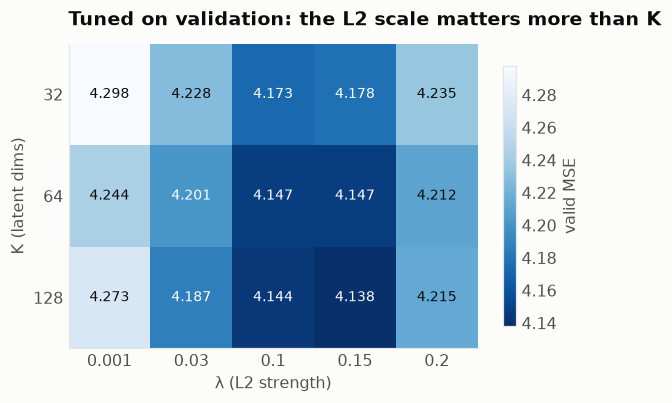

In [36]:
report.fig_tuning_heatmap(); plt.show()

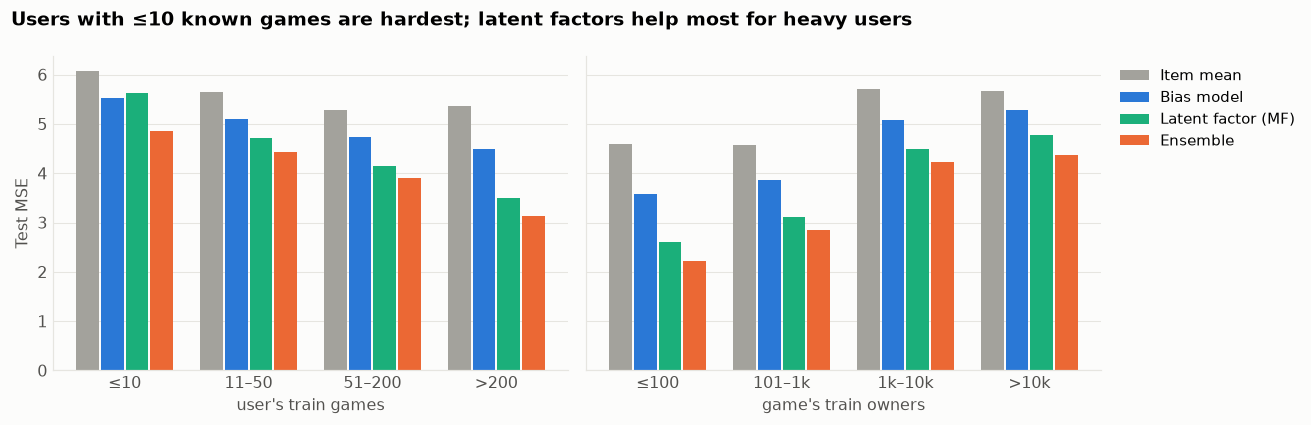

In [37]:
from steam.regression_stack import breakdown
bd = breakdown("test")
report.fig_breakdown(bd); plt.show()

### Are the predictions trustworthy? Calibration and ranking within a library
Low MSE alone does not show that predictions are *usable*. We check (1) calibration: within each bin of predicted
playtime, does the actual playtime match on average? (2) whether the model orders a user's *own* games correctly.

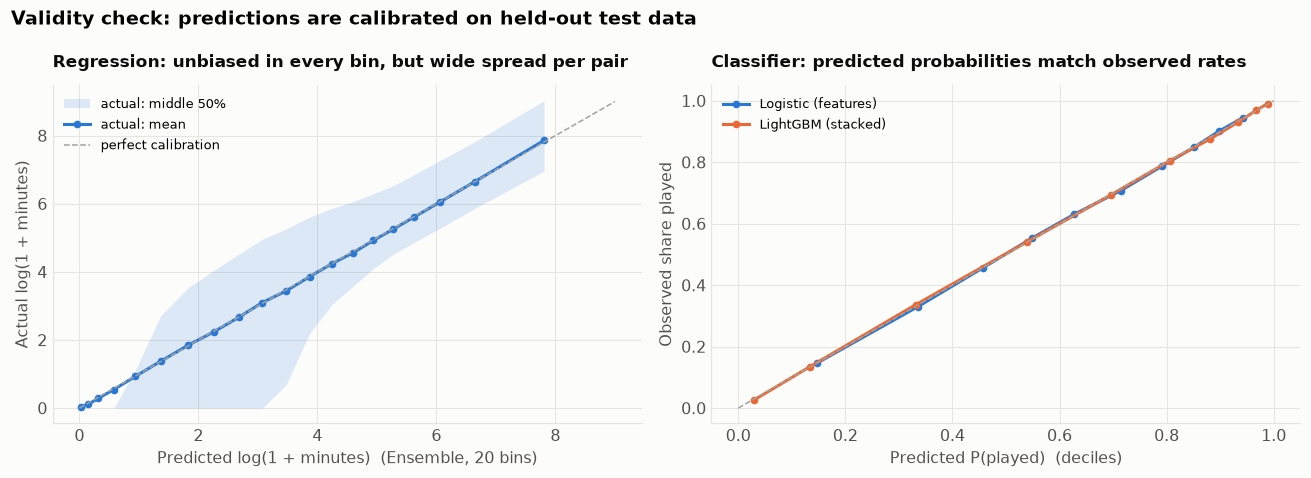

,value
RMSE (log scale),1.963
typical error factor e^RMSE,7.120
"Spearman, all test pairs",0.756
median within-user Spearman (≥5 test games),0.700
users in within-user check,30453.000


In [38]:
report.fig_calibration(); plt.show()
report.calibration_stats().round(3)

**Reading this honestly.** The predictions are **unbiased** in every bin and the classifier's probabilities match observed
rates, so downstream decisions (e.g. "show games with P(play) > 0.8") behave as intended. The model also orders a user's own
library well (within-user rank correlation around 0.7). But the **spread for a single pair is wide**: an RMSE near 2 on
the log scale is a typical miss of several-fold in hours. Two reasons, neither fixable by a better learner alone:
(1) **the zero spike**: for an uncertain game, the MSE-optimal prediction hedges between "never launched" and "played",
which is exactly why we model P(played) separately (hurdle) and report AUC/BER for it; (2) **taste is noisy**: similar
users put 2 vs 200 hours into the same game. What the models predict well is *relative engagement*, not exact hours.

### Cold start: games never seen in training

In [39]:
cold = report.table_regression("cold")
display(report.style_table(cold, best_low=["MSE", "MAE"]))

,MSE,MAE,vs global mean
Global mean,10.8494,2.8979,0.0000
User mean,9.0843,2.5497,0.1627
Item mean,10.8494,2.8979,0.0000
Bias model,9.9543,2.7113,0.0825
Latent factor (MF),10.1342,2.7731,0.0659
Factorization machine,10.8845,2.7114,-0.0032
LightGBM (stacked),10.7200,2.6998,0.0119
LightGBM (metadata only),7.4355,2.1765,0.3147
Hurdle (LightGBM),10.8416,2.6876,0.0007
CatBoost (stacked),9.3557,2.5393,0.1377


Collaborative models collapse on unseen games: the stacked models were trained where game statistics always exist.
The **metadata-only LightGBM** is the only regression model that clearly beats the user-mean baseline here. Whether a game
is in the training data is known at prediction time, so the deployable system **routes never-seen games to the
metadata-only model** and everything else to the ensemble:

In [40]:
c = report.table_regression("cold"); t = report.table_regression("test")
display(Markdown(f"Routed system: test MSE **{t.loc['Ensemble','MSE']:.3f}** (warm games, ensemble) and cold MSE "
                 f"**{c.loc['LightGBM (metadata only)','MSE']:.3f}** (vs {c.loc['Ensemble','MSE']:.3f} if the ensemble were used on cold games, "
                 f"and {c.loc['User mean','MSE']:.3f} for the user-mean baseline)."))

Routed system: test MSE **3.853** (warm games, ensemble) and cold MSE **7.435** (vs 9.280 if the ensemble were used on cold games, and 9.084 for the user-mean baseline).

## 4.2 Will they play it? (classification)

In [41]:
for t in ["played", "active"]:
    display(Markdown(f"**Target: `{t}`**"))
    display(report.style_table(report.table_classification(t), best_high=["AUC", "Accuracy"], best_low=["BER"]))

**Target: `played`**

,AUC,BER,Accuracy,threshold
Item rate (baseline),0.8225,0.2596,0.7448,0.6254
User rate (baseline),0.7034,0.3512,0.6547,0.6286
Logistic (features),0.8024,0.2756,0.7195,0.6354
Logistic (+ CF scores),0.8976,0.1860,0.8187,0.6299
LightGBM (stacked),0.9029,0.1817,0.8227,0.6275


**Target: `active`**

,AUC,BER,Accuracy,threshold
Item rate (baseline),0.8472,0.2299,0.7731,0.0273
User rate (baseline),0.7241,0.3260,0.6679,0.0256
Logistic (features),0.8149,0.2620,0.7522,0.0265
Logistic (+ CF scores),0.8794,0.2018,0.7953,0.0247
LightGBM (stacked),0.8998,0.1815,0.7960,0.0235


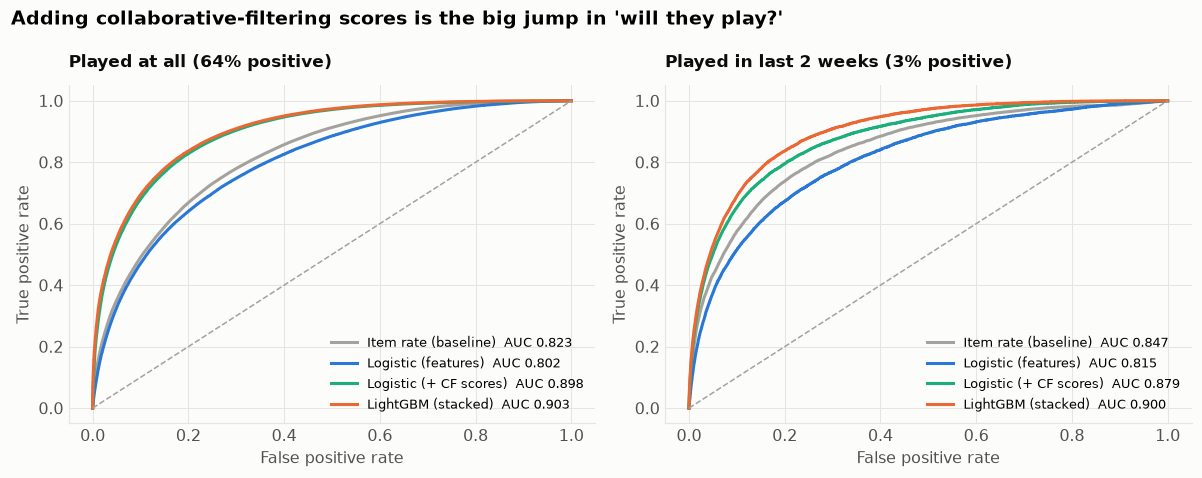

In [42]:
report.fig_roc(); plt.show()

## 4.3 Recommending games they will play (ranking)

In [43]:
for p, title in [("test", "Standard protocol (1 played vs 99 not-owned)"),
                 ("hard", "Hard protocol (1 played vs 9 owned-but-unplayed)"),
                 ("cold", "Cold-start protocol (never-seen games)")]:
    display(Markdown(f"**{title}**"))
    display(report.style_table(report.table_ranking(p), best_high=["AUC", "HR@1", "HR@3", "HR@10", "NDCG@1", "NDCG@3", "NDCG@10"]))

**Standard protocol (1 played vs 99 not-owned)**

,AUC,HR@1,NDCG@1,HR@10,NDCG@10
Random,0.4993,0.0102,0.0102,0.0995,0.0453
Most popular,0.9646,0.4270,0.4270,0.8973,0.6536
Jaccard item-kNN,0.9672,0.4899,0.4899,0.9146,0.6987
ALS (binary),0.9389,0.5192,0.5192,0.8985,0.7108
ALS (playtime-weighted),0.9404,0.5053,0.5053,0.8980,0.7042
BPR-MF,0.9042,0.3516,0.3516,0.7774,0.5529
item2vec,0.9492,0.4124,0.4124,0.8525,0.6252
Content (tf-idf),0.7911,0.2152,0.2152,0.6272,0.4068
Hybrid (ALS + content),0.9451,0.5071,0.5071,0.9011,0.7065
LTR reranker (LightGBM),0.9829,0.5961,0.5961,0.9608,0.7819


**Hard protocol (1 played vs 9 owned-but-unplayed)**

,AUC,HR@1,NDCG@1,HR@3,NDCG@3
Random,0.5062,0.1060,0.1060,0.3110,0.2211
Most popular,0.6970,0.2868,0.2868,0.5588,0.4424
Jaccard item-kNN,0.7362,0.3329,0.3329,0.6217,0.4994
ALS (binary),0.7347,0.2982,0.2982,0.6178,0.4828
ALS (playtime-weighted),0.7431,0.3014,0.3014,0.6323,0.4927
BPR-MF,0.6661,0.2466,0.2466,0.5159,0.4021
item2vec,0.7578,0.3507,0.3507,0.6577,0.5289
Content (tf-idf),0.6551,0.2252,0.2252,0.5245,0.3967
Hybrid (ALS + content),0.7502,0.3073,0.3073,0.6407,0.4994
LTR reranker (LightGBM),0.7624,0.3581,0.3581,0.6572,0.5313


**Cold-start protocol (never-seen games)**

,AUC,HR@1,NDCG@1,HR@10,NDCG@10
Random,0.4983,0.0099,0.0099,0.0994,0.0451
Most popular,0.5000,0.0000,0.0000,0.0000,0.0000
Predicted popularity (content),0.9352,0.3490,0.3490,0.7335,0.5219
Content (tf-idf),0.9120,0.3414,0.3414,0.7616,0.5463
ALS factors mapped from content,0.9325,0.3842,0.3842,0.8217,0.5902
Hybrid (mapped ALS + content),0.9444,0.4212,0.4212,0.8506,0.6281


**Reading the ranking tables.**
- *Standard protocol:* popularity and Jaccard are hard to beat because the held-out game is usually a hit. Tuned ALS is the
  best single model on NDCG; the **LambdaRank reranker** beats every single model by learning *when* to trust kNN, ALS
  or popularity (its most-used inputs are the per-user z-scores of Jaccard, ALS and popularity).
- *Hard protocol:* every recommender drops sharply, because popularity can no longer separate the candidates (they are all owned).
  The **Task 4 played-classifier** is by far the best ranker here: it was trained on exactly this question and uses
  the user's own play rate, genre affinity and the CF scores.
- *Cold start:* only content-aware models work; mapping content to ALS factors and blending with tf-idf similarity is best.
- *BPR* trails ALS even after tuning learning rate, L2 and epochs (`implicit`'s BPR samples negatives uniformly, which
  mostly teaches it popularity); with sampled metrics it is the weakest collaborative model.

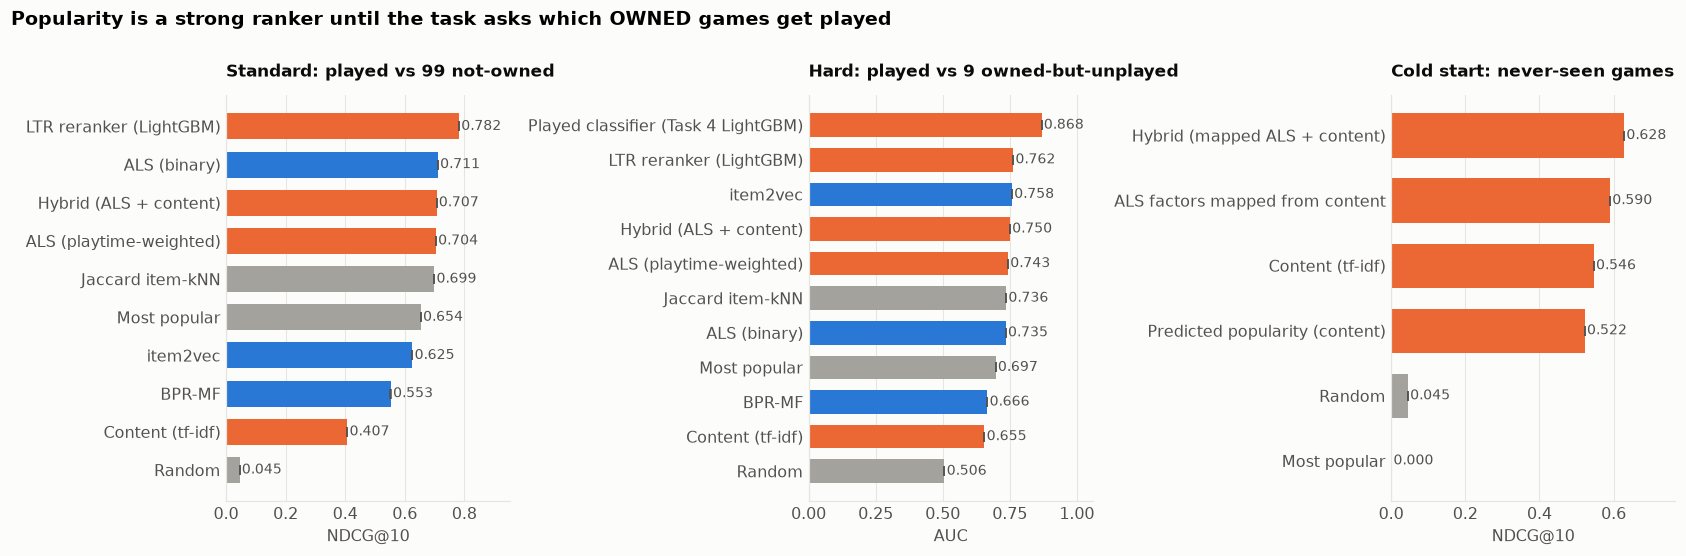

In [44]:
report.fig_ranking(); plt.show()

In [45]:
R = report.load("ranking")
pd.DataFrame({m: {k: f"{np.mean(v):.4f} ± {np.std(v):.4f}" for k, v in d.items()} for m, d in R["seeds"].items()}).T

,AUC,HR@1,NDCG@1,HR@10,NDCG@10
ALS (playtime-weighted),0.9400 ± 0.0003,0.5054 ± 0.0009,0.5054 ± 0.0009,0.8978 ± 0.0004,0.7040 ± 0.0006
ALS (binary),0.9385 ± 0.0005,0.5195 ± 0.0006,0.5195 ± 0.0006,0.8976 ± 0.0009,0.7107 ± 0.0002
BPR-MF,0.9048 ± 0.0005,0.3521 ± 0.0013,0.3521 ± 0.0013,0.7788 ± 0.0011,0.5541 ± 0.0011


**Is the reranker's gain significant, and what does it use?** Paired bootstrap over test users (1,000 resamples) of the
per-user NDCG@10 difference, and the reranker's feature importance (share of total split gain).

In [46]:
display(report.table_ltr_significance().round(4))
display(report.ltr_importance().round(3))

,ΔNDCG@10 (LTR − model),95% CI low,95% CI high,significant
Most popular,0.1283,0.1259,0.1304,yes
Jaccard item-kNN,0.0832,0.0813,0.0853,yes
ALS (binary),0.0711,0.0692,0.0730,yes
ALS (playtime-weighted),0.0777,0.0758,0.0797,yes
BPR-MF,0.2290,0.2260,0.2318,yes
item2vec,0.1567,0.1543,0.1590,yes
Content (tf-idf),0.3751,0.3717,0.3785,yes


,share of gain
z: Jaccard item-kNN,0.620
z: ALS (binary),0.171
z: Most popular,0.113
z: BPR-MF,0.039
BPR-MF,0.023
z: ALS (playtime-weighted),0.011
Most popular,0.009
ALS (binary),0.002
z: item2vec,0.002
item2vec,0.002


## 4.4 Ablations: what each component is worth

,task,variant,component,value,metric,Δ vs full
0,Regression,Full ensemble,–,3.8528,MSE,0.0000
1,Regression,− hurdle stage (plain stacked LightGBM),hurdle,3.8617,MSE,0.0089
2,Regression,− collaborative signal (metadata-only LightGBM),CF,5.0802,MSE,1.2274
3,Regression,− metadata & stacking (MF alone),metadata,4.1504,MSE,0.2976
4,Ranking (hard),ALS playtime-weighted,–,0.7431,AUC,0.0000
5,Ranking (hard),− playtime weighting (binary ALS),playtime,0.7347,AUC,-0.0084
6,Ranking (hard),+ Task 4 played-classifier instead,classifier,0.8682,AUC,0.1251
7,Ranking (standard),ALS playtime-weighted,–,0.7042,NDCG@10,0.0000
8,Ranking (standard),− playtime weighting (binary ALS),playtime,0.7108,NDCG@10,0.0066
9,Ranking (standard),+ content features (hybrid),content,0.7065,NDCG@10,0.0023


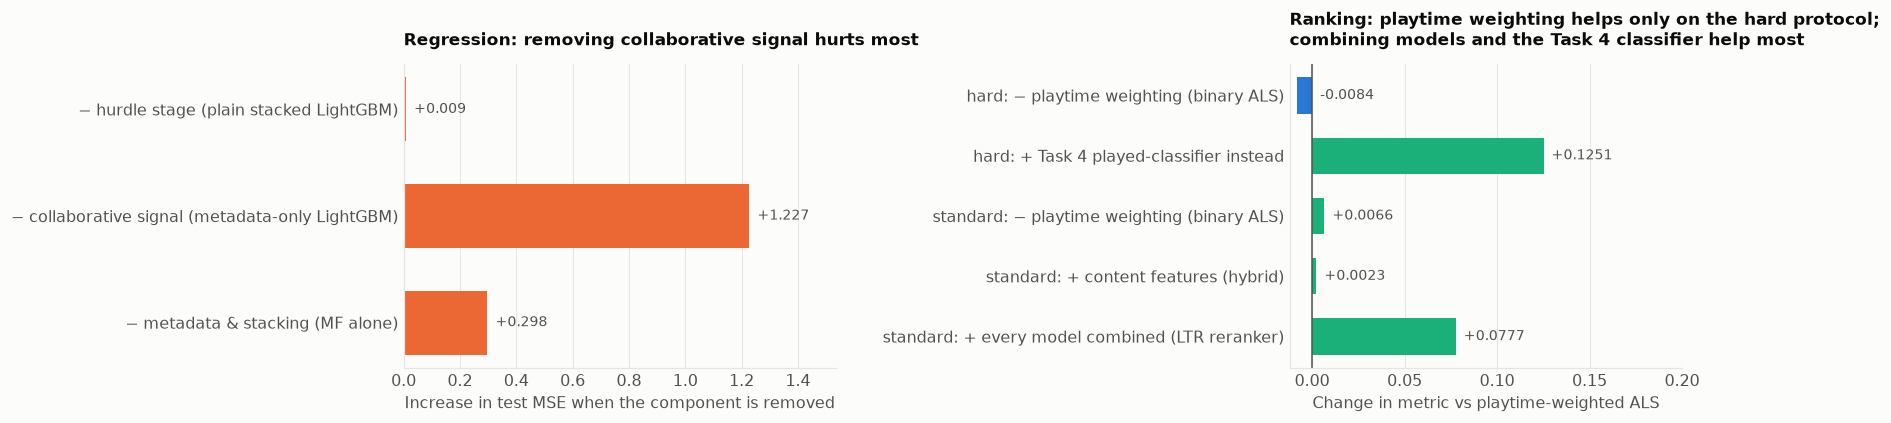

In [47]:
display(report.ablations().round(4))
report.fig_ablation(); plt.show()

## 4.5 Popularity bias and diversity

,coverage,head_share,novelty
Most popular,0.006,1.000,7.332
Jaccard item-kNN,0.041,0.968,7.831
BPR-MF,0.287,0.165,11.845
ALS (binary),0.107,0.568,9.002
ALS (playtime-weighted),0.111,0.556,9.070
item2vec,0.057,0.690,10.328
Content (tf-idf),0.102,0.123,11.511
Hybrid (ALS + content),0.107,0.564,9.043


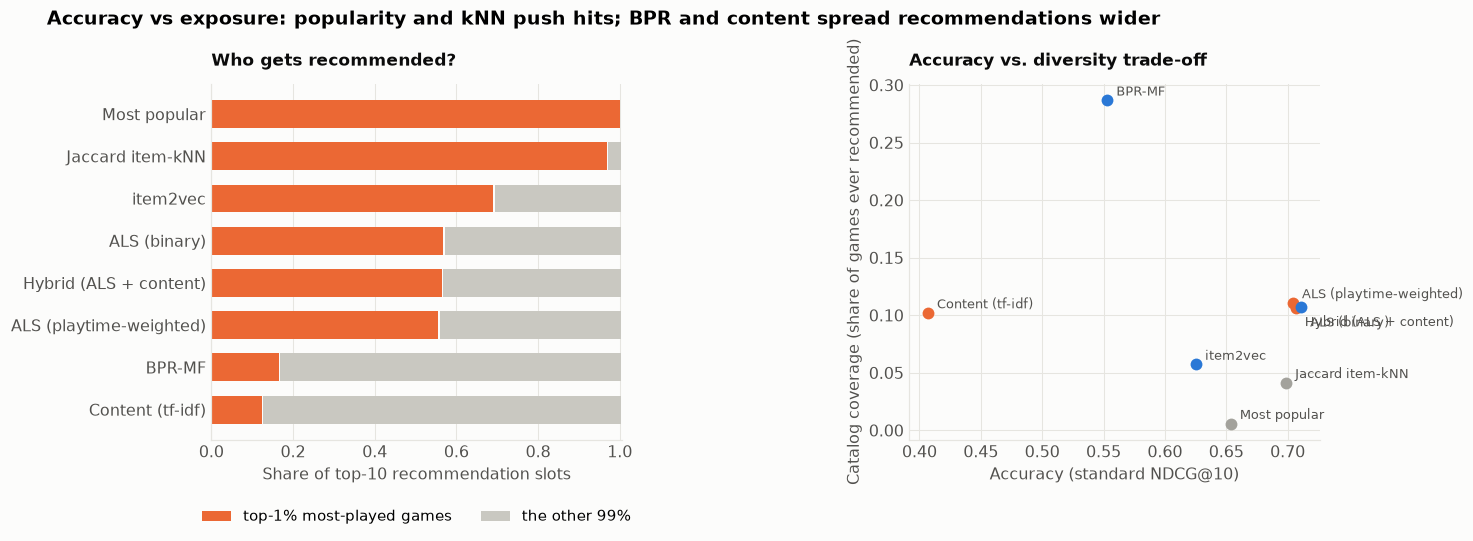

In [48]:
display(pd.DataFrame(report.load("ranking")["beyond"]).T.round(3))
report.fig_popularity_bias(); plt.show()

Accuracy on sampled metrics rewards recommending hits, since the held-out positive is usually popular. The table shows the
price: the more accurate models concentrate recommendations on the top 1% of games, while content-based models spread
exposure across the catalog. For a store this is a real trade-off (ethics lecture): long-tail and indie developers get
little exposure from accuracy-optimized recommenders.

## 4.6 Error analysis

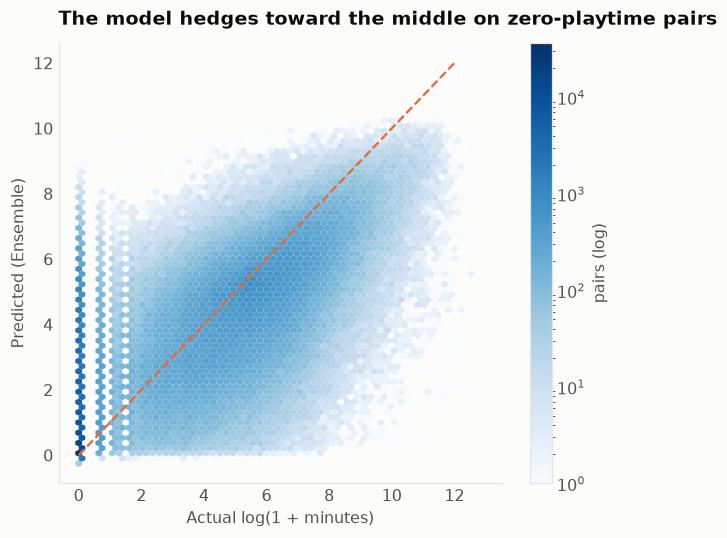

,game,actual hours,predicted hours,free,user library size
0,9th Company: Roots Of Terror,1071.400024,0.0,0.0,1576.0
1,Fallout: New Vegas,1624.599976,0.1,0.0,342.0
2,The Darkness II,1974.500000,0.1,0.0,323.0
3,Elsword,2272.199951,0.1,1.0,20.0
4,Gems of War - Puzzle RPG,400.399994,0.0,1.0,2691.0
5,Day of Defeat,1888.199951,0.1,0.0,389.0
6,(no metadata) id 219540,479.799988,0.0,NaN,135.0
7,Shroud of the Avatar: Forsaken Virtues,1457.300049,0.1,0.0,225.0


In [49]:
fig, worst = report.fig_errors(); plt.show(); worst

The largest errors are pairs with huge actual playtime that the model predicted as barely played, or the reverse.
Typical causes are idle or AFK games left running, free-to-play games, and users with enormous libraries whose behavior
is idiosyncratic. Predictions shrink toward the middle for the zero-playtime mass, which is the expected behavior of
an MSE-optimal model under uncertainty.

## 4.7 A concrete example

In [50]:
lib, recs = report.user_card()
display(Markdown("**This user's most-played games**")); display(lib)
display(Markdown("**Top-5 recommendations (playtime-weighted ALS), with an explanation**")); display(recs)

**This user's most-played games**

,most played games,hours
0,Fallout: New Vegas,153
1,Fallout 4,112
2,Counter-Strike: Global Offensive,110
3,METAL GEAR SOLID V: THE PHANTOM PAIN,68
4,STAR WARS™ - Knights of the Old Republic™,43
5,(unknown),22


**Top-5 recommendations (playtime-weighted ALS), with an explanation**

,recommended,genres,because you played,similarity
0,"Star Wars: Battlefront 2 (Classic, 2005)",Action,STAR WARS™ - Knights of the Old Republic™,0.72
1,Portal 2,"Action, Adventure",Killing Floor,0.88
2,Borderlands 2,"Action, RPG",Chivalry: Medieval Warfare,0.99
3,(unknown),,Chivalry: Medieval Warfare,0.47
4,Fallout 3: Game of the Year Edition,RPG,Fallout 4,0.84


# 5. Related work

In [51]:
report.table_related_work()

,Work,Data,Task,Method,Metric,How we compare
0,"Kang & McAuley 2018 (SASRec, ICDM)","Steam (this crawl, larger version)",Next-item prediction,Self-attentive sequential model,"HR@10 / NDCG@10, 100 sampled negatives","Same sampled protocol. We rank by library (no order); SASRec reports most-popular is a weak baseline, but here popul..."
1,Wan & McAuley 2018 (RecSys),Steam (this dataset),Monotonic behavior chains (purchase → play → review),Chain-aware BPR variants,AUC,Our 'owned vs played' split is one link of their chain; we confirm play signal is separate from ownership
2,"Pathak, Gupta & McAuley 2017 (SIGIR)",Steam bundles,Bundle recommendation,BPR + bundle generation,"AUC, recall",We use bundles only for EDA; bundle scoring is a planned extension
3,"Koren, Bell & Volinsky 2009",Netflix,Rating prediction,Biased matrix factorization,RMSE,"Our bias → MF ladder mirrors theirs: biases capture most of the gain, factors add more"
4,"Hu, Koren & Volinsky 2008",TV viewing,Implicit feedback,Confidence-weighted ALS,Expected rank,Playtime as confidence helps on our hard protocol (owned-but-unplayed negatives) but not on the standard one
5,Rendle 2009 (BPR),"Rossmann, Netflix",Implicit ranking,Pairwise BPR loss,AUC,"BPR beats popularity on AUC in their paper; here, even after tuning, BPR trails popularity, ALS and item2vec"
6,Rendle 2010 (FM),Various,Sparse regression,Factorization machines,RMSE,FM adds metadata; helps cold start more than warm accuracy
7,Barkan & Koenigstein 2016 (item2vec),"Microsoft Store, music",Item similarity,Skip-gram on item sets,Similarity quality,"Our item2vec orders libraries by playtime, as in HW4; best single recommender on the hard protocol"
8,Burges 2010 (LambdaMART),Web search (LETOR),Learning to rank,Gradient-boosted trees with lambda gradients,NDCG,Our LambdaRank reranker over all base recommenders is the best model on the standard protocol


**How this dataset has been used.** The Steam crawl was introduced for sequential recommendation (SASRec; Kang & McAuley 2018),
for modeling chains of implicit signals such as purchase → play → review (Wan & McAuley 2018), and for bundle
recommendation (Pathak et al. 2017). Most prior work treats *ownership or interaction* as the positive signal.
Our framing makes the gap between owning and playing the object of study.

**How our results compare.**
- As in Koren et al. (2009), **biases capture a large share of the gain**, and latent factors add a further improvement.
- Hu et al. (2008) argue that **interaction strength should set confidence**. In our data, playtime-weighted ALS beats binary ALS
  on the *hard* protocol (choosing among owned games), but not on the standard protocol. Playtime helps decide which owned game
  gets played; it does not help predict which unowned game gets picked up.
- Ordering a library by playtime (item2vec, as in HW4) gives the best *single-signal recommender* on the hard protocol:
  embeddings that encode what a user plays *most* transfer to what they will play at all. But a supervised model trained
  on the actual question (our Task 4 classifier) beats every recommender there by a wide margin.
- As in the learning-to-rank literature (Burges 2010) and in Netflix Prize blends, **combining complementary rankers**
  beats any single one: the LambdaRank reranker improves NDCG@10 over the best single model by a statistically clear margin.
- Unlike SASRec's results, where most-popular is a weak baseline, **popularity is very strong** on the standard sampled
  protocol here. Libraries overlap heavily, and sampled metrics are known to favor popular items (Krichene & Rendle 2020).
  Our **hard protocol** removes this advantage and shows where personalization really matters.

# Takeaways and limitations

In [52]:
reg = report.table_regression("test"); rk = report.load("ranking")["results"]
best = reg.MSE.idxmin()
hb = max(rk["hard"], key=lambda m: rk["hard"][m]["AUC"])
ts = max(rk["test"], key=lambda m: rk["test"][m]["NDCG@10"])
single = max([m for m in rk["test"] if "LTR" not in m], key=lambda m: rk["test"][m]["NDCG@10"])
display(Markdown(f'''
1. **Owning ≠ playing.** {eda.glance().set_index("Statistic").loc["Owned games never played","Value"]} of owned games are never played,
   and engagement depends on price, genre and the user's own history.
2. **Playtime is predictable.** {best} reaches test MSE {reg.loc[best,"MSE"]:.3f} vs {reg.loc["Global mean","MSE"]:.3f} for the global mean
   ({1 - reg.loc[best,"MSE"] / reg.loc["Bias model","MSE"]:.0%} below the course bias model). Collaborative signal is by far
   the most valuable component; implicit-feedback affinities (ALS, item2vec) add to the explicit MF; the hurdle split adds a small further gain.
3. **Recommend for play, not purchase.** Popularity looks excellent on the standard protocol (AUC {rk["test"]["Most popular"]["AUC"]:.3f})
   but drops to {rk["hard"]["Most popular"]["AUC"]:.3f} when asked which *owned* games get played; {hb} reaches {rk["hard"][hb]["AUC"]:.3f}.
4. **Combine, then specialize.** {ts} reaches standard NDCG@10 {rk["test"][ts]["NDCG@10"]:.3f} vs {rk["test"][single]["NDCG@10"]:.3f}
   for the best single model ({single}); for owned games, the Task 4 classifier is the right tool.
5. **Regularization scale matters.** Our first MF/FM grids used λ values ~1/4000 of the loss; fixing the scale removed MF's
   overfitting and was the largest single gain for the main task.
'''))


1. **Owning ≠ playing.** 36.3% of owned games are never played,
   and engagement depends on price, genre and the user's own history.
2. **Playtime is predictable.** Ensemble reaches test MSE 3.853 vs 9.124 for the global mean
   (19% below the course bias model). Collaborative signal is by far
   the most valuable component; implicit-feedback affinities (ALS, item2vec) add to the explicit MF; the hurdle split adds a small further gain.
3. **Recommend for play, not purchase.** Popularity looks excellent on the standard protocol (AUC 0.965)
   but drops to 0.697 when asked which *owned* games get played; Played classifier (Task 4 LightGBM) reaches 0.868.
4. **Combine, then specialize.** LTR reranker (LightGBM) reaches standard NDCG@10 0.782 vs 0.711
   for the best single model (ALS (binary)); for owned games, the Task 4 classifier is the right tool.
5. **Regularization scale matters.** Our first MF/FM grids used λ values ~1/4000 of the loss; fixing the scale removed MF's
   overfitting and was the largest single gain for the main task.


**Limitations / next steps:** a single split seed for the regression models (bootstrap intervals cover test-set noise but
not training randomness; seed error bars exist only for the ranking factor models); the regression is limited to owned pairs;
there is no temporal split (the crawl is a snapshot, so a sequential model like SASRec would need review timestamps); the
cold-start FM was not trained with id-dropout; sampled ranking metrics favor popular items (Krichene & Rendle 2020), and we did
not measure the reranker's catalog coverage; BPR remains weak with uniform negative sampling; per-pair hour predictions
remain wide (see calibration), so the models are best used to *rank* and to estimate *probability of play*.